# Прогнозирование оттока абонентов телеком-оператора

**Проектный практикум · команда № 2 · кейс № 2**

Оператору требуется оценить вероятность ухода каждого абонента и определить характеристики, связанные с повышенным риском. Это задача бинарной классификации. Одна строка описывает одного клиента. Целевая переменная `Churn` отмечает уход за последний месяц.

### Участники команды

- Тимур Кармеев
- Вадим Семенов
- Катрина Ефимова
- Григорий Китаев
- Святослав Тюрин
- Алексей Щербаха

### Содержание

1. **Разделы 1–9.** Данные, разведочный анализ (EDA) и гипотезы для моделирования.
2. **Разделы 10–16.** Базовая модель, эксперименты и выбор конфигурации.
3. **Разделы 17–19.** Итоговая проверка, приоритеты обзвона, факторы риска и экономика кампании.

### Вклад в работу

Это совместная работа всех шести участников команды. Команда провела разведочный анализ, сформулировала гипотезы об оттоке и проверила их в модельных экспериментах. Мы сравнили модели и способы балансировки классов, оценили итоговую модель на отложенной выборке и выделили факторы, связанные с повышенной долей ухода.

[Условие кейса](https://github.com/ozzzpo/imo-practicum/blob/4d79ad6/context/case-02.md) · [Источник данных](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

## 1. Данные и воспроизводимость

Используем CSV **Telco Customer Churn, версия 1**. Ячейка читает CSV рядом с ноутбуком или из папки данных проекта. Если файла там нет, KaggleHub скачает его с Kaggle. Контрольная сумма помогает сверить файл с версией, на которой рассчитаны результаты.

Для просмотра достаточно открыть ноутбук с сохранёнными таблицами и графиками. Для повторного расчёта выберите ядро Python 3.12 с зависимостями и выполните **Restart Kernel → Run All Cells**.

**В PyCharm.** Если выбрано проектное окружение `.venv` с уже установленными зависимостями, для моделирования дополнительно установите `imbalanced-learn`. Выполните команду из корня проекта.

```powershell
uv pip install --python .\.venv\Scripts\python.exe imbalanced-learn==0.14.2
```

<details>
<summary>Повторный расчёт вне проекта</summary>

Откройте терминал в папке с ноутбуком. Если установлен `uv`, эта команда запустит JupyterLab с проверенными версиями библиотек.

```text
uv run --no-project --isolated --python 3.12.16 --with pandas==3.1.1 --with numpy==2.5.4 --with scipy==1.18.1 --with matplotlib==3.11.2 --with seaborn==0.13.2 --with phik==0.12.5 --with kagglehub==1.0.3 --with scikit-learn==1.9.1 --with imbalanced-learn==0.14.2 --with ipywidgets==8.1.9 --with jupyterlab==4.6.6 --with ipykernel==7.4.0 --with threadpoolctl==3.8.0 jupyter lab
```

Откройте ноутбук в JupyterLab и запустите все ячейки.

</details>

| Группа | Поля и смысл |
|---|---|
| Идентификатор | `customerID` — ID абонента |
| Демография | `gender`, `SeniorCitizen` (флаг 0/1), `Partner`, `Dependents` |
| Договор | `tenure` — месяцы обслуживания; `Contract` — срок договора; `PaperlessBilling` — электронный счёт |
| Телефония | `PhoneService`, `MultipleLines` |
| Интернет | `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Начисления и оплата | `PaymentMethod` — способ оплаты; `MonthlyCharges` — текущая месячная плата; `TotalCharges` — накопленные начисления |
| Цель | `Churn` — уход за последний месяц по описанию набора, `Yes` / `No` |

Истории тарифов и отдельных транзакций, дат первого счёта и причин ухода
в этом CSV нет. `No internet service` и `No phone service` — содержательные
категории отсутствия основной услуги.

In [1]:
from hashlib import sha256
from pathlib import Path

import pandas as pd

filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
local_paths = [
    Path(filename),                          # CSV рядом с ноутбуком
    Path("../data/raw") / filename,          # запуск из notebooks/
    Path("data/raw") / filename,             # запуск из корня проекта
]
csv_path = next((path for path in local_paths if path.is_file()), None)
if csv_path is None:
    import kagglehub

    csv_path = Path(kagglehub.dataset_download(
        "blastchar/telco-customer-churn/versions/1", path=filename,
    ))

expected_sha256 = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"
if sha256(csv_path.read_bytes()).hexdigest() != expected_sha256:
    raise ValueError("Используйте исходный CSV Telco Customer Churn версии 1 с Kaggle.")

raw = pd.read_csv(csv_path)
print(f"Загружен {csv_path.name}. Строк — {raw.shape[0]:,}, столбцов — {raw.shape[1]}.")

Загружен WA_Fn-UseC_-Telco-Customer-Churn.csv. Строк — 7,043, столбцов — 21.


Посмотрим пять случайных записей и типы столбцов сразу после чтения CSV. Фиксируем `random_state`, чтобы при повторном запуске увидеть тех же клиентов. Для анализа создадим рабочую копию `df`.

In [2]:
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import phik  # добавляет метод .phik_matrix() к DataFrame
from IPython.display import display

df = raw.copy(deep=True)
INTERNET_EXTRAS = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]
PAYMENT_ORDER = [
    "Electronic check", "Mailed check",
    "Bank transfer (automatic)", "Credit card (automatic)",
]
BLUE, ORANGE = "#4C78A8", "#E68A2E"
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.precision", 3)

display(df.sample(5, random_state=42).T)
df.info()

,185,2715,3825,1807,132
customerID,1024-GUALD,0484-JPBRU,3620-EHIMZ,6910-HADCM,8587-XYZSF
gender,Female,Male,Female,Female,Male
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,Yes,No,No
Dependents,No,No,Yes,No,No
tenure,1,41,52,1,67
PhoneService,No,Yes,Yes,Yes,Yes
MultipleLines,No phone service,Yes,No,No,No
InternetService,DSL,No,No,Fiber optic,DSL
OnlineSecurity,No,No internet service,No internet service,No,No


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

В таблице 7 043 абонента и 21 поле. `tenure` и `MonthlyCharges` имеют числовой тип. `SeniorCitizen` хранится как число 0 или 1 и по смыслу обозначает категорию. Столбец `TotalCharges` содержит сумму начислений, но pandas прочитал его как текст. Проверим исходные значения перед преобразованием.

## 2. Качество данных

### 2.1. Пропуски и допустимые значения

Сначала ищем пропуски, которые pandas распознал при чтении CSV. Затем проверяем все текстовые столбцы на пустые строки и строки из одних пробелов. Такие строки могут выглядеть как пустые ячейки, хотя `isna()` их не учитывает.

In [3]:
recognized_missing = df.isna().sum()
recognized_missing = recognized_missing[recognized_missing.gt(0)]
if recognized_missing.empty:
    print("Распознанных пропусков нет.")
else:
    display(recognized_missing.to_frame("Распознанные пропуски"))

blank_text = {}
for column in df.select_dtypes(include=["object", "string"]).columns:
    # После удаления пробелов по краям проверяем, остался ли текст.
    blank_text[column] = df[column].str.strip().eq("").fillna(False)

blank_counts = pd.Series(
    {column: mask.sum() for column, mask in blank_text.items()},
    name="Пустые и пробельные строки",
)
display(blank_counts[blank_counts.gt(0)].to_frame())

Распознанных пропусков нет.


,Пустые и пробельные строки
TotalCharges,11


Пробельные значения нашлись только в `TotalCharges`, их 11. Посмотрим, что известно об этих абонентах. Для наглядности выведем текстовое значение в кавычках, чтобы в таблице был виден пробел.

In [4]:
missing_total = df["TotalCharges"].isna() | blank_text["TotalCharges"]
columns_to_inspect = ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
affected_clients = df.loc[missing_total, columns_to_inspect].copy()
affected_clients["TotalCharges"] = affected_clients["TotalCharges"].map(repr)
display(affected_clients)
print("Всего клиентов с tenure = 0:", int(df["tenure"].eq(0).sum()))

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,' ',Two year,No
753,3115-CZMZD,0,20.25,' ',Two year,No
936,5709-LVOEQ,0,80.85,' ',Two year,No
1082,4367-NUYAO,0,25.75,' ',Two year,No
1340,1371-DWPAZ,0,56.05,' ',Two year,No
3331,7644-OMVMY,0,19.85,' ',Two year,No
3826,3213-VVOLG,0,25.35,' ',Two year,No
4380,2520-SGTTA,0,20.00,' ',Two year,No
5218,2923-ARZLG,0,19.70,' ',One year,No
6670,4075-WKNIU,0,73.35,' ',Two year,No


Всего клиентов с tenure = 0: 11


У всех 11 абонентов с пробельным `TotalCharges` стаж равен нулю. В датасете эти клиенты отмечены как `Churn = No`. Возможно, начислений к этому моменту ещё не было. Дата первого счёта нам неизвестна, поэтому в EDA сохраним сумму как пропуск.

Теперь заменим найденные пробельные значения на `NaN`, а остальные суммы преобразуем в числа. Для модели подстановка нуля при нулевом стаже будет отдельным шагом пайплайна.

In [5]:
total_charges = df["TotalCharges"].mask(missing_total)
df["TotalCharges"] = pd.to_numeric(total_charges)

print("Тип TotalCharges после преобразования —", df["TotalCharges"].dtype)
print("Пропусков в TotalCharges —", int(df["TotalCharges"].isna().sum()))

Тип TotalCharges после преобразования — float64
Пропусков в TotalCharges — 11


Теперь можно проверить диапазоны числовых признаков и допустимые значения категорий. `SeniorCitizen` подпишем как `Yes` и `No` в рабочей таблице для графиков.

In [6]:
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]

df["SeniorCitizen"] = raw["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("category")
expected = {
    col: {"Yes", "No"}
    for col in ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
}
expected.update({col: {"Yes", "No", "No internet service"} for col in INTERNET_EXTRAS})
expected.update({
    "gender": {"Female", "Male"},
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "Contract": set(CONTRACT_ORDER),
    "PaymentMethod": set(PAYMENT_ORDER),
})
category_checks = pd.DataFrame([
    {"feature": col, "unexpected_n": int((df[col].notna() & ~df[col].isin(values)).sum()),
     "missing_n": int(df[col].isna().sum())}
    for col, values in expected.items()
]).set_index("feature")
print("Проверено категориальных полей:", len(category_checks))
print("Недопустимые категории:", int(category_checks["unexpected_n"].sum()))
print("Пропуски в категориях:", int(category_checks["missing_n"].sum()))
print("Отрицательные значения:", df[NUMERIC].lt(0).sum().to_dict())
print("Нецелые tenure:", int(df["tenure"].mod(1).ne(0).sum()))

Проверено категориальных полей: 17
Недопустимые категории: 0
Пропуски в категориях: 0
Отрицательные значения: {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}
Нецелые tenure: 0


После преобразования в `TotalCharges` появились 11 распознанных пропусков. Проверки не показали недопустимых категорий, отрицательных числовых значений или дробного стажа. В `raw` сохранены исходные типы и значения из CSV, а дальнейший EDA использует рабочую таблицу `df`.

### 2.2. Дубликаты и совпадающие профили

Проверим, повторяется ли целая запись или идентификатор абонента. Затем посмотрим, встречаются ли у разных абонентов одинаковые **профили**. Профиль здесь — значения всех 19 признаков клиента. Отдельно проверим, совпадает ли у таких клиентов и исход `Churn`.

**Как читать таблицу.** Группа совпадений — две или более строки, у которых совпадают все поля из выбранной проверки. Например, если у трёх клиентов одинаковы все 19 признаков, в последней строке таблицы это **3 строки и 1 группа**. После сводки покажем один такой профиль, в котором были и ушедшие, и оставшиеся клиенты.

In [7]:
def duplicate_summary(frame, columns):
    # keep=False отмечает каждую строку, у которой есть совпадение.
    rows_in_groups = frame.duplicated(subset=columns, keep=False)
    # Из совпавших строк берём по одному набору значений на группу.
    distinct_groups = frame.loc[rows_in_groups, columns].drop_duplicates()
    return {
        "Строк в группах": int(rows_in_groups.sum()),
        "Групп совпадений": len(distinct_groups),
    }


profile_with_target = df.columns.drop("customerID").tolist()
feature_columns = df.columns.drop(["customerID", "Churn"]).tolist()
duplicate_checks = pd.DataFrame.from_dict({
    "Вся запись": duplicate_summary(df, df.columns.tolist()),
    "Идентификатор абонента": duplicate_summary(df, ["customerID"]),
    "19 признаков и исход оттока": duplicate_summary(df, profile_with_target),
    "Только 19 признаков клиента": duplicate_summary(df, feature_columns),
}, orient="index").rename_axis("Что сравниваем")
display(duplicate_checks)

profiles = df.groupby(feature_columns, observed=True, dropna=False)
outcomes_per_profile = profiles["Churn"].nunique()
different_outcomes = outcomes_per_profile[outcomes_per_profile.gt(1)]
print(f"Групп, в которых есть ушедшие и оставшиеся клиенты — {len(different_outcomes)}.")

if not different_outcomes.empty:
    example = profiles.get_group(different_outcomes.index[0])
    example_columns = {
        "customerID": "ID абонента",
        "tenure": "Стаж, мес.",
        "Contract": "Договор",
        "MonthlyCharges": "Месячная плата",
        "Churn": "Ушёл ли клиент",
    }
    example_table = example[list(example_columns)].rename(columns=example_columns)
    example_table["Ушёл ли клиент"] = example_table["Ушёл ли клиент"].map({"Yes": "Да", "No": "Нет"})
    print("Пример одной группы. Совпадают все 19 признаков, ниже показаны три признака из всех для удобства.")
    display(example_table.reset_index(drop=True))

,Строк в группах,Групп совпадений
Что сравниваем,,
Вся запись,0,0
Идентификатор абонента,0,0
19 признаков и исход оттока,42,20
Только 19 признаков клиента,73,33


Групп, в которых есть ушедшие и оставшиеся клиенты — 18.
Пример одной группы. Совпадают все 19 признаков, ниже показаны три признака из всех для удобства.


,ID абонента,"Стаж, мес.",Договор,Месячная плата,Ушёл ли клиент
0,5692-FPTAH,1,Month-to-month,45.4,Да
1,2275-RBYQS,1,Month-to-month,45.4,Нет


Каждая полная запись и каждый `customerID` уникальны. При сравнении только признаков **73 абонента образуют 33 группы** одинаковых профилей. Если требовать совпадения и по `Churn`, остаются **42 абонента в 20 группах**.
В **18 из 33 групп** есть и ушедшие, и оставшиеся клиенты. В примере видно, что у абонентов разные ID и разные исходы при одинаковых признаках. Сохраняем обе записи, как и остальные совпавшие профили. Для модели такие клиенты выглядят одинаково по доступным признакам, поэтому она присвоит им одинаковую вероятность ухода.

### 2.3. Согласованность основных и дополнительных услуг

Проверим, согласуются ли сведения об услугах у каждого абонента. Например, `OnlineSecurity` показывает, подключена ли интернет-защита. Если у клиента есть интернет, в этом поле ожидаем `Yes` (защита подключена) или `No` (защита не подключена). Если интернета нет, ожидаем отметку `No internet service`. По этому правилу проверяем все шесть дополнительных интернет-услуг.

Для телефонии проверяем поля `PhoneService` и `MultipleLines`. При подключённой телефонии `MultipleLines` показывает, есть ли у клиента несколько линий. При отсутствии телефонии в этом поле ожидаем отметку `No phone service`.

In [8]:
service_checks = []
for main, extra, absent_label in [
    ("PhoneService", "MultipleLines", "No phone service"),
    *[("InternetService", col, "No internet service") for col in INTERNET_EXTRAS],
]:
    main_absent = df[main].eq("No")
    extra_absent = df[extra].eq(absent_label)
    service_checks.append({
        "feature": extra,
        "main_absent_n": int(main_absent.sum()),
        "special_category_n": int(extra_absent.sum()),
        "absent_main_wrong_status_n": int((main_absent & ~extra_absent).sum()),
        "present_main_special_status_n": int((~main_absent & extra_absent).sum()),
    })
service_checks = pd.DataFrame(service_checks).set_index("feature")
display(service_checks)

,main_absent_n,special_category_n,absent_main_wrong_status_n,present_main_special_status_n
feature,,,,
MultipleLines,682,682,0,0
OnlineSecurity,1526,1526,0,0
OnlineBackup,1526,1526,0,0
DeviceProtection,1526,1526,0,0
TechSupport,1526,1526,0,0
StreamingTV,1526,1526,0,0
StreamingMovies,1526,1526,0,0


В проверенных парах несогласованных записей нет: у всех 682 клиентов
без телефонии стоит `No phone service`; у всех 1 526 клиентов без
интернета во всех шести дополнительных полях — `No internet service`.
У остальных клиентов специальные категории не встречаются.

Отсутствие основной услуги повторяется в нескольких признаках.
Это объясняет часть их тесных связей. При этом `No` и `No internet service`
имеют разный смысл; объединять их в EDA нельзя. Дополнительные поля
содержат и сведения о подключённых опциях, поэтому сама эта зависимость
ещё не обосновывает удаление столбцов.

### 2.4. Проверка накопленных начислений

В разделе 2.1 мы нашли 11 пропущенных значений `TotalCharges` у клиентов с нулевым стажем. Теперь проверим известные суммы. Хотим понять, соразмерны ли накопленные начисления тому, сколько месяцев клиент пользуется услугами и сколько платит в месяц сейчас.

**Гипотеза.** Если месячная плата была примерно такой же с начала обслуживания, накопленная сумма должна быть близка к `tenure × MonthlyCharges`. Например, при стаже 6 месяцев и плате 50 в месяц ориентир составит 300. Для сравнения берём клиентов с известным `TotalCharges` и стажем больше нуля.

На левом графике сравниваем расчётный ориентир с суммой из CSV. Точка на диагонали означает, что суммы равны. На правом графике показываем, во сколько раз сумма из CSV больше или меньше ориентира. Значение 1 означает равенство, 0,90 — сумму на 10% ниже ориентира, 1,10 — на 10% выше. Интервал от 0,90 до 1,10 помогает посчитать, сколько клиентов находятся близко к ориентиру.

,ratio
count,7032.000
mean,1.000
std,0.051
min,0.689
5%,0.924
25%,0.980
50%,1.000
75%,1.020
95%,1.075
max,1.573


В пределах ±10%: 6651 / 7032 = 94.58%


,customerID,tenure,MonthlyCharges,TotalCharges,reference_total,ratio,difference,relative_difference_pct
5595,2308-STERM,2,19.4,61.05,38.8,1.573,22.25,57.345
869,0323-XWWTN,3,26.4,121.25,79.2,1.531,42.05,53.093
5673,6260-XLACS,4,19.7,117.80,78.8,1.495,39.00,49.492
4689,2832-SCUCO,2,19.9,57.40,39.8,1.442,17.60,44.221


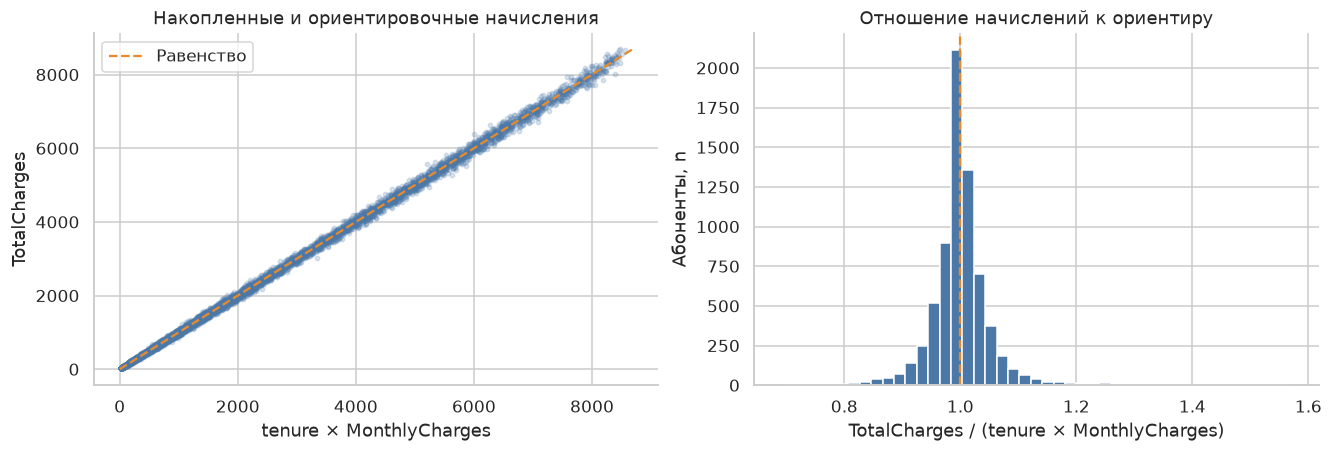

In [9]:
charge_check = df.loc[
    df["TotalCharges"].notna() & df["tenure"].gt(0),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"],
].copy()
charge_check["reference_total"] = charge_check["tenure"] * charge_check["MonthlyCharges"]
charge_check["ratio"] = charge_check["TotalCharges"] / charge_check["reference_total"]
charge_check["difference"] = charge_check["TotalCharges"] - charge_check["reference_total"]
charge_check["relative_difference_pct"] = (charge_check["ratio"] - 1) * 100
display(charge_check["ratio"].describe(percentiles=[.05, .25, .5, .75, .95]).to_frame())
within_ten_pct = charge_check["ratio"].between(.9, 1.1)
print(f"В пределах ±10%: {within_ten_pct.sum()} / {len(charge_check)} = {within_ten_pct.mean():.2%}")
extreme_rows = charge_check["relative_difference_pct"].abs().nlargest(4).index
display(charge_check.loc[extreme_rows].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].scatter(charge_check["reference_total"], charge_check["TotalCharges"], s=8, alpha=.2, color=BLUE)
limit = max(charge_check["reference_total"].max(), charge_check["TotalCharges"].max())
axes[0].plot([0, limit], [0, limit], linestyle="--", color=ORANGE, label="Равенство")
axes[0].set(xlabel="tenure × MonthlyCharges", ylabel="TotalCharges", title="Накопленные и ориентировочные начисления")
axes[0].legend()
axes[1].hist(charge_check["ratio"], bins=45, color=BLUE)
axes[1].axvline(1, color=ORANGE, linestyle="--")
axes[1].set(xlabel="TotalCharges / (tenure × MonthlyCharges)", ylabel="Абоненты, n", title="Отношение начислений к ориентиру")
plt.show()

У **6 651 из 7 032 клиентов (94,58%)** накопленная сумма отличается от ориентира в пределах ±10%. Медиана отношения близка к 1. Значит, для большинства клиентов накопленные начисления соразмерны стажу и текущей плате.

Самое большое относительное расхождение видно у абонента `2308-STERM`. При стаже 2 месяца и текущей плате 19,40 ориентир равен 38,80, а в CSV указано 61,05. Разница составляет 22,25, или 57,35% от ориентира. Для выяснения причины потребовалась бы история начислений и изменений тарифа. В данных сохраняем известные суммы из CSV. Произведение стажа и месячной платы служит ориентиром для сравнения.

## 3. Целевая переменная

Сначала считаем размеры и доли классов. Во всех последующих сравнениях
доля оттока — это число `Churn = Yes`, делённое на число клиентов
внутри рассматриваемой группы.

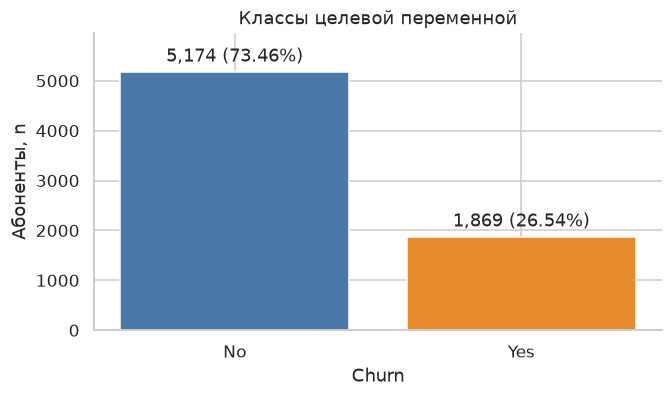

In [10]:
class_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
overall_churn_pct = df["Churn"].eq("Yes").mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
bars = ax.bar(class_counts.index, class_counts.values, color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(df):.2%})" for n in class_counts], padding=4)
ax.set(xlabel="Churn", ylabel="Абоненты, n", title="Классы целевой переменной", ylim=(0, class_counts.max() * 1.15))
plt.show()

Ушли 1 869 из 7 043 клиентов — 26,54%, остались 5 174 — 73,46%.
Предсказание «все остаются» уже даст Accuracy 73,46%, поэтому одной
Accuracy недостаточно. При моделировании нужно оценивать обнаружение
оттока и качество вероятностей. В разделе 10 выбираем ROC-AUC основной
метрикой и откладываем 20% клиентов для проверки. Класс каждого клиента в EDA сохраняется.

## 4. Распределения признаков

### 4.1. Числовые признаки и выбросы

`describe`, гистограммы и boxplot строятся на исходных значениях.
В расчётах `TotalCharges` используются 7 032 известных значения;
для двух остальных признаков — все 7 043 строки.

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


,lower,upper,outside_n
feature,,,
tenure,-60.00,124.00,0
MonthlyCharges,-46.02,171.38,0
TotalCharges,-4688.48,8884.67,0


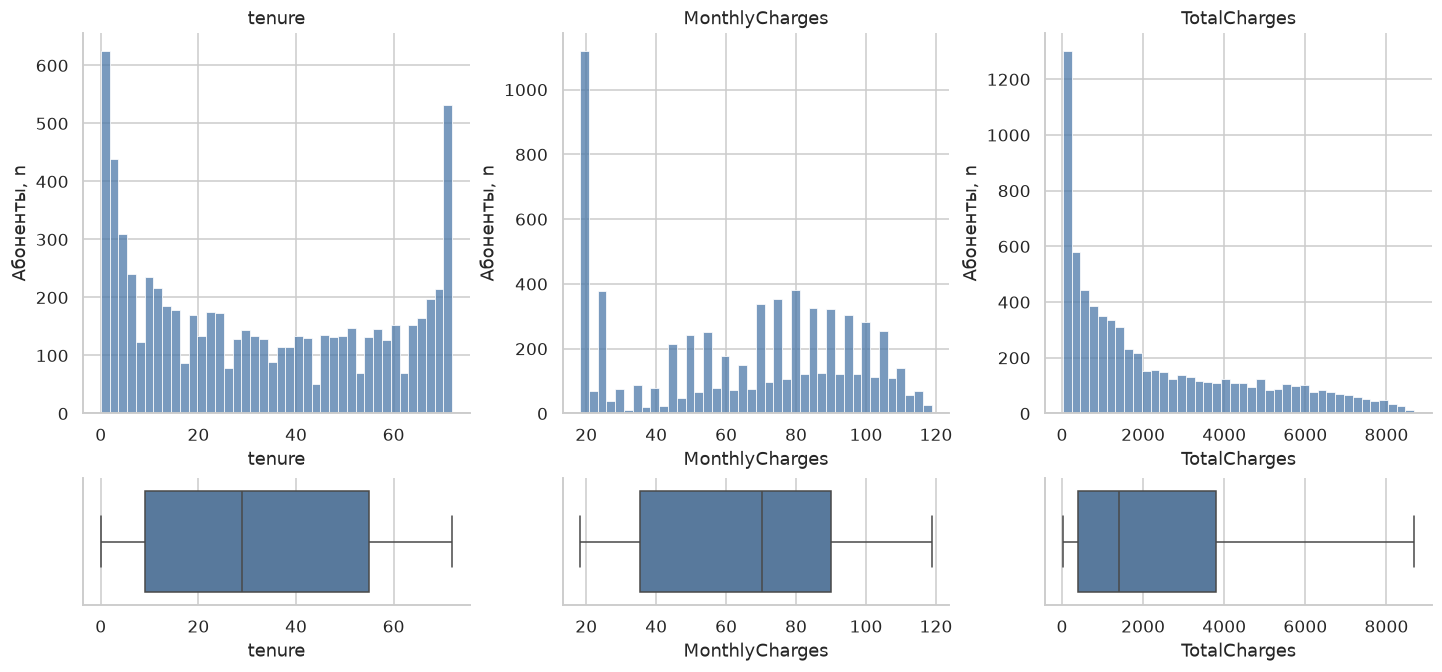

In [11]:
display(df[NUMERIC].describe().round(2))
iqr_rows = []
for col in NUMERIC:
    values = df[col].dropna()
    q1, q3 = values.quantile([.25, .75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr_rows.append({"feature": col, "lower": lower, "upper": upper,
                     "outside_n": int((~values.between(lower, upper)).sum())})
display(pd.DataFrame(iqr_rows).set_index("feature").round(2))

fig, axes = plt.subplots(2, 3, figsize=(13, 6), layout="constrained", height_ratios=[3, 1])
for i, col in enumerate(NUMERIC):
    sns.histplot(data=df, x=col, bins=40, ax=axes[0, i], color=BLUE)
    axes[0, i].set(title=col, xlabel=col, ylabel="Абоненты, n")
    sns.boxplot(data=df, x=col, ax=axes[1, i], color=BLUE)
    axes[1, i].set(xlabel=col, ylabel="")
plt.show()

`tenure` лежит в диапазоне 0–72 месяца, медиана — 29 месяцев;
заметны скопления клиентов с малым и большим сроком обслуживания.
Месячные начисления лежат в диапазоне 18,25–118,75, медиана — 70,35.
`TotalCharges` имеет длинный правый хвост: это накопительная сумма,
и большой счёт может объясняться сроком и стоимостью услуг.

На всей выборке для каждого из трёх признаков наблюдений вне
границ 1,5 IQR нет. Это результат конкретной проверки, а не доказательство
отсутствия любых ошибок. Усы boxplot внутри отдельных групп могут
быть другими. Автоматическая фильтрация по IQR не применяется.

### 4.2. Частоты категорий

В предыдущем разделе мы посмотрели, как распределяются стаж и начисления. Теперь изучим состав выборки по категориям. Например, выясним, какие договоры распространены, сколько клиентов пользуются интернетом и насколько велики разные группы оплаты. Размер каждой группы пригодится, когда будем сравнивать отток.

На каждом графике одна полоса соответствует одной категории, а число справа показывает количество абонентов. `SeniorCitizen` уже подписан как `Yes` и `No`. Распределение `Churn` мы посмотрели отдельно в разделе 3.

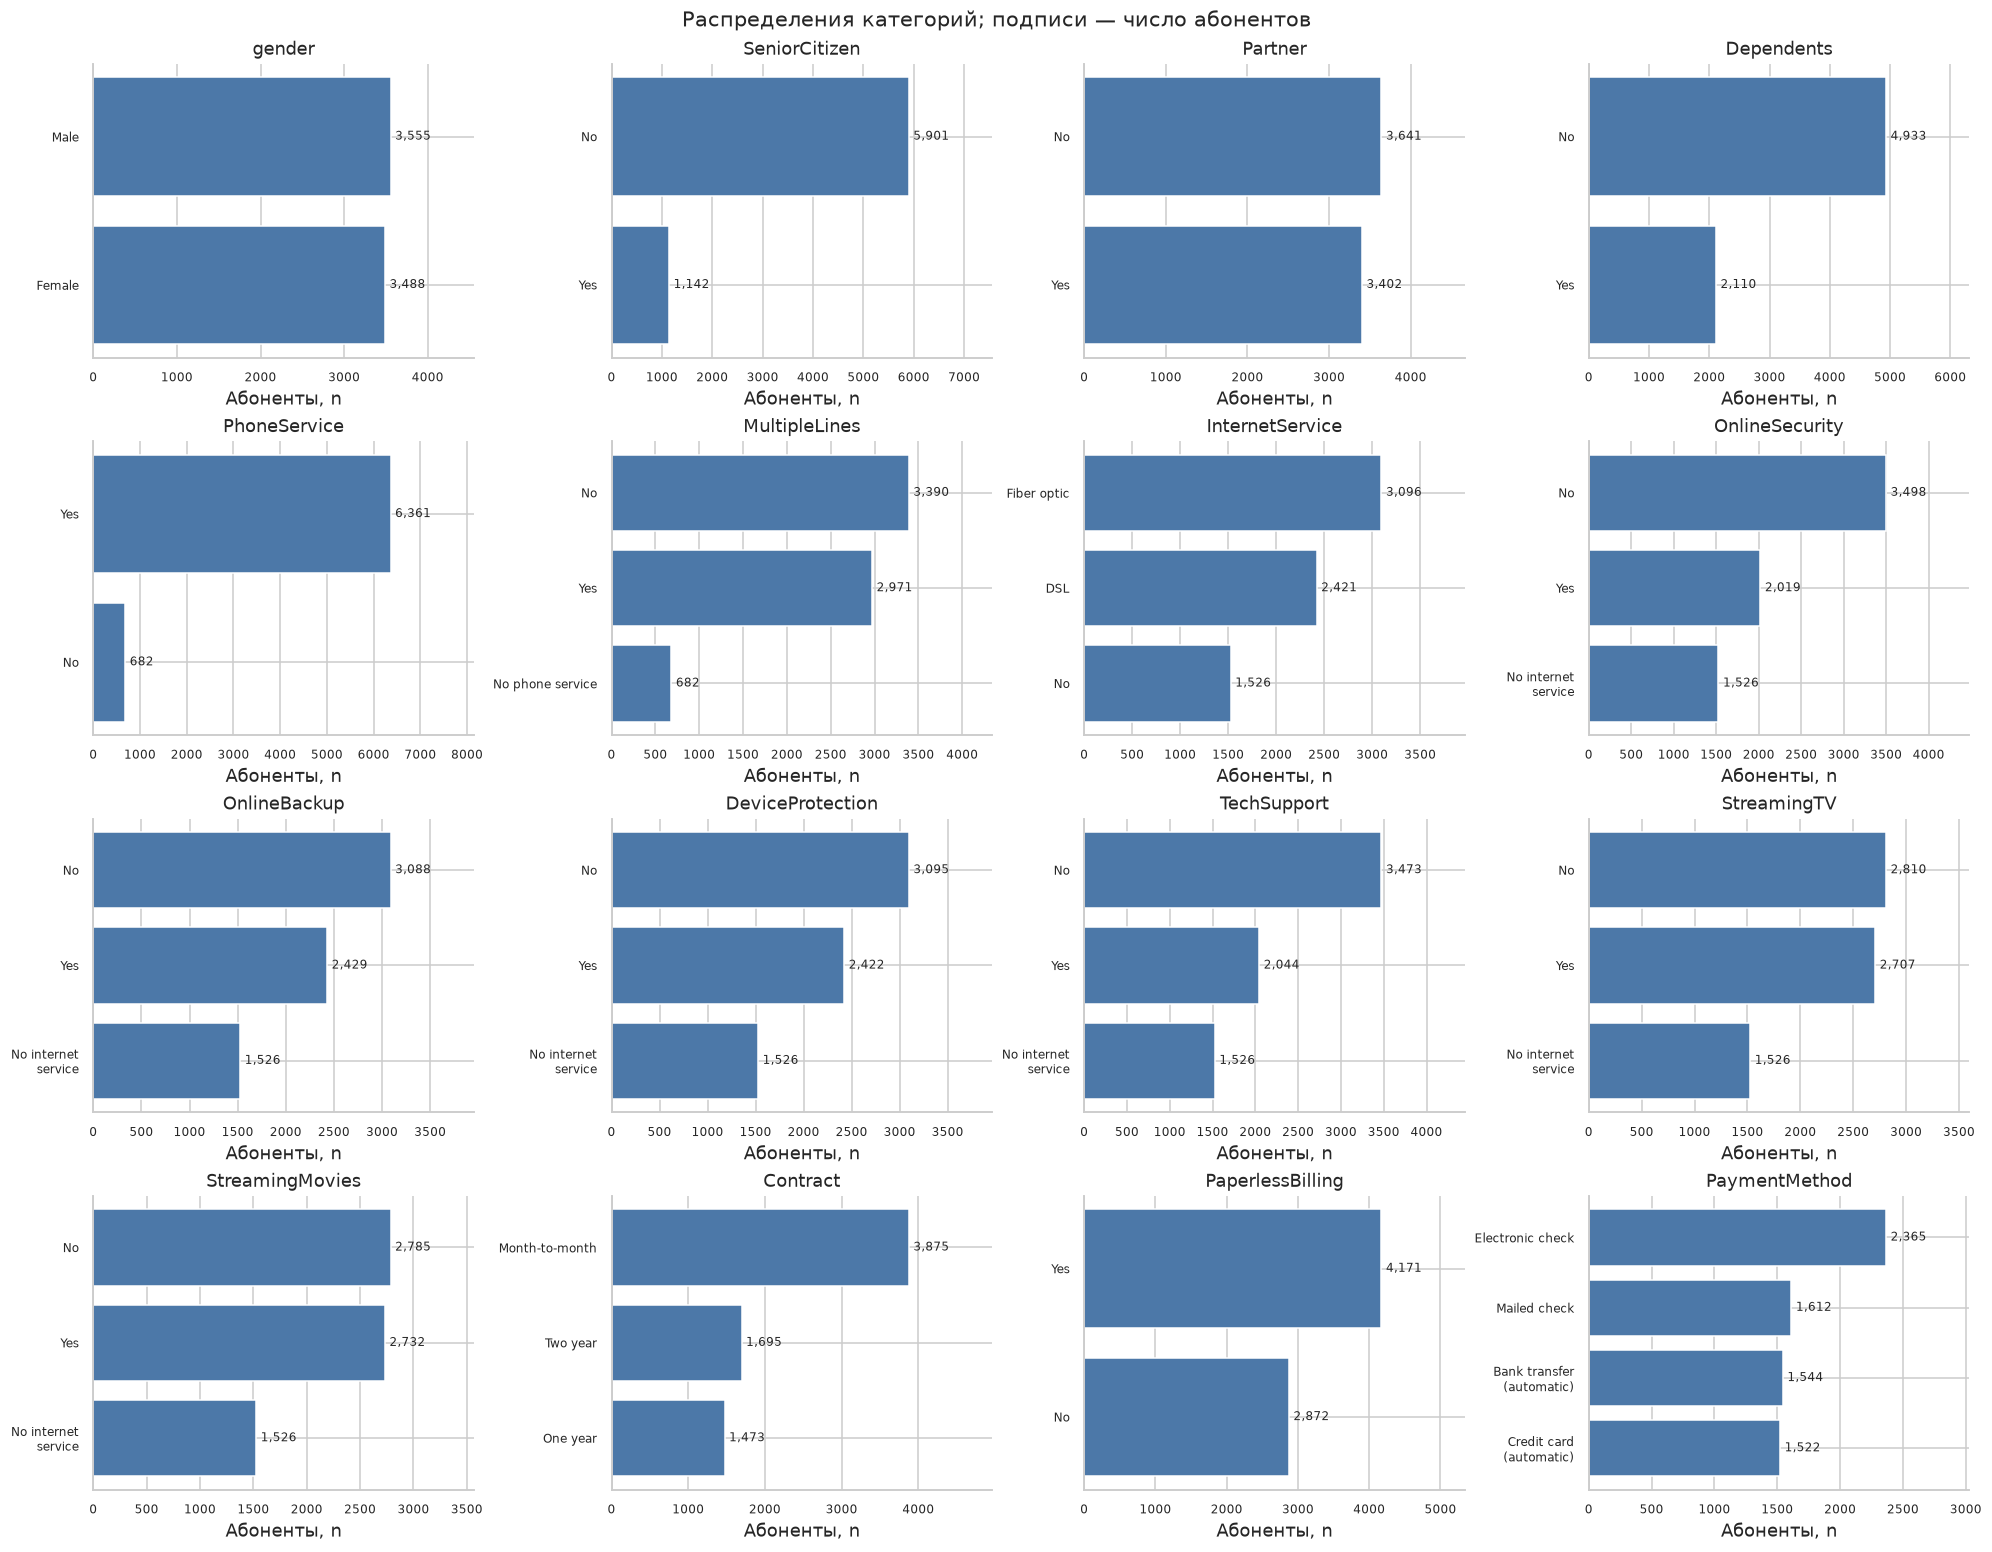

In [12]:
categorical_cols = [col for col in df.columns if col not in ["customerID", "Churn", *NUMERIC]]
fig, axes = plt.subplots(4, 4, figsize=(18, 14), layout="constrained")
for ax, col in zip(axes.flat, categorical_cols):
    counts = df[col].value_counts()
    positions = np.arange(len(counts))
    bars = ax.barh(positions, counts.values, color=BLUE)
    ax.set_yticks(positions, [fill(str(label), 17) for label in counts.index])
    ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3, fontsize=8)
    ax.invert_yaxis()
    ax.set(title=col, xlabel="Абоненты, n", xlim=(0, counts.max() * 1.28))
    ax.tick_params(labelsize=8)
fig.suptitle("Распределения категорий; подписи — число абонентов", fontsize=14)
plt.show()


Самая крупная группа по типу договора — клиенты с помесячным договором. Их **3 875 из 7 043**, а с годовым и двухлетним договорами — 1 473 и 1 695 соответственно. Интернет подключён у 5 517 абонентов. Чаще всего среди способов оплаты встречается `Electronic check` — 2 365 клиентов. Мужчины и женщины представлены примерно поровну, а отметка `SeniorCitizen = Yes` есть у 1 142 абонентов.

Число ушедших зависит и от размера группы. При одинаковой доле оттока в более многочисленной группе уйдёт больше клиентов. Поэтому при сравнении договоров и других категорий дальше будем делить число ушедших на размер соответствующей группы. Размеры групп покажем рядом с долями.

## 5. Связь признаков с оттоком

### 5.1. Числовые признаки по группам Churn

Раньше мы смотрели на признаки по всей выборке. Теперь сравним клиентов с `Churn = Yes` (ушли) и `Churn = No` (остались). Проверим, отличаются ли у них стаж, месячная плата и накопленные начисления. Так получим первые гипотезы о том, какие числовые признаки помогают различать эти группы.

В таблице для каждой группы покажем медиану. Она делит упорядоченные значения примерно пополам и удобна для сравнения начислений, у которых есть крупные значения. На графике линия внутри каждого ящика отмечает медиану, а сам ящик охватывает средние 50% значений. Так видно и различие между типичными значениями, и то, насколько похожи диапазоны у двух групп.

,clients_n,tenure,MonthlyCharges,TotalCharges,known_TotalCharges_n
Churn,,,,,
No,5174,38.0,64.425,1683.60,5163
Yes,1869,10.0,79.650,703.55,1869


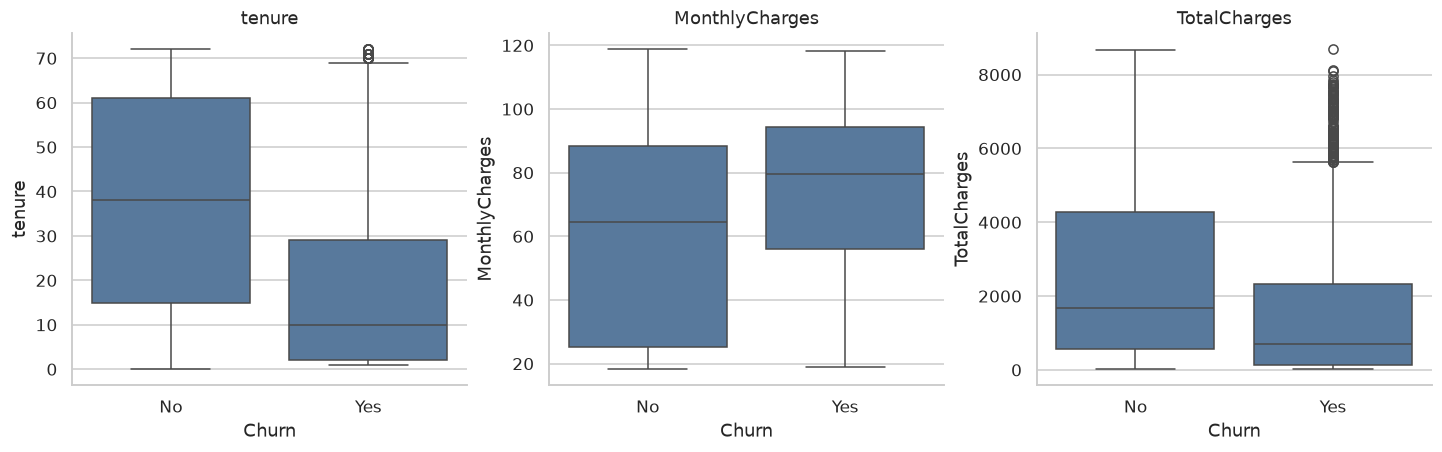

In [13]:
medians = df.groupby("Churn")[NUMERIC].median()
medians.insert(0, "clients_n", df.groupby("Churn").size())
medians["known_TotalCharges_n"] = df.groupby("Churn")["TotalCharges"].count()
display(medians.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], ax=ax, color=BLUE)
    ax.set(title=col, xlabel="Churn", ylabel=col)
plt.show()


У ушедших клиентов медианный стаж **10 месяцев**, у оставшихся — **38 месяцев**. При этом медианная месячная плата у ушедших выше — **79,650** против **64,425**. Накопленная сумма у них ниже — **703,55** против **1 683,60**. Это согласуется с тем, что у клиентов с меньшим стажем было меньше времени накопить начисления. У оставшихся медиана `TotalCharges` рассчитана по 5 163 известным суммам.

На графиках диапазоны двух групп перекрываются. По одному стажу или месячной плате можно увидеть общую закономерность, а среди клиентов со схожими значениями встречаются оба исхода. Дальше в разделе 5.2 посмотрим, какая доля клиентов ушла в каждом диапазоне стажа и месячной платы.

### 5.2. Доли оттока по интервалам срока и месячной платы

Границы интервалов заданы для описания данных, не подбираются по метрике
модели. Группа `0–12` включает и `tenure = 0`; границы стоимости подписаны
с указанием включённой правой границы. Это диапазоны начислений,
а не названия реальных тарифов.

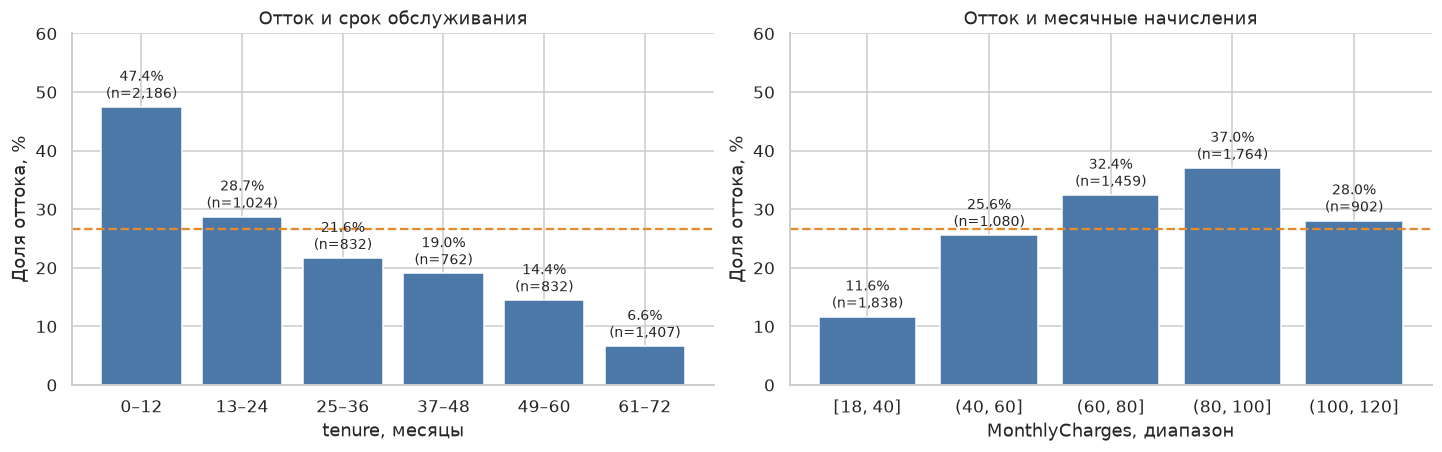

In [14]:
def churn_summary(frame, by):
    result = (
        frame.assign(_churned=frame["Churn"].eq("Yes"))
        .groupby(by, observed=True, dropna=False)["_churned"]
        .agg(n="size", churned="sum")
    )
    result["churn_pct"] = result["churned"] / result["n"] * 100
    return result


segments = df.assign(
    tenure_group=pd.cut(df["tenure"], bins=[0, 12, 24, 36, 48, 60, 72],
                        labels=["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"],
                        include_lowest=True),
    charges_group=pd.cut(df["MonthlyCharges"], bins=[18, 40, 60, 80, 100, 120],
                         labels=["[18, 40]", "(40, 60]", "(60, 80]", "(80, 100]", "(100, 120]"],
                         include_lowest=True),
)
tenure_summary = churn_summary(segments, "tenure_group")
charges_summary = churn_summary(segments, "charges_group")
assert segments[["tenure_group", "charges_group"]].notna().all().all()
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for ax, table, title, xlabel in [
    (axes[0], tenure_summary, "Отток и срок обслуживания", "tenure, месяцы"),
    (axes[1], charges_summary, "Отток и месячные начисления", "MonthlyCharges, диапазон"),
]:
    bars = ax.bar(table.index.astype(str), table["churn_pct"], color=BLUE)
    ax.bar_label(bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in zip(table["churn_pct"], table["n"])], padding=3, fontsize=9)
    ax.axhline(overall_churn_pct, linestyle="--", color=ORANGE)
    ax.set(title=title, xlabel=xlabel, ylabel="Доля оттока, %", ylim=(0, 60))
plt.show()

В группе 0–12 месяцев отток составляет 47,44% (1 037 / 2 186),
в группе 61–72 — 6,61% (93 / 1 407). На выбранных 12-месячных
интервалах доля последовательно снижается.

По месячной плате зависимость не строго возрастающая: при начислениях
(80, 100] отток 37,02% (653 / 1 764), при (100, 120] — 28,05%
(253 / 902). Различия могут быть связаны с составом услуг, договорами
и сроком обслуживания. По этим снимкам нельзя оценивать вероятность
ухода одного и того же клиента на каждом месяце жизни.

### 5.3. Доли оттока по всем категориям

Для каждой категории показываем процент и размер группы `n`.
Пунктир — общая доля оттока 26,54%. Одинаковая шкала позволяет
сравнивать панели; сами эти сравнения остаются одномерными.

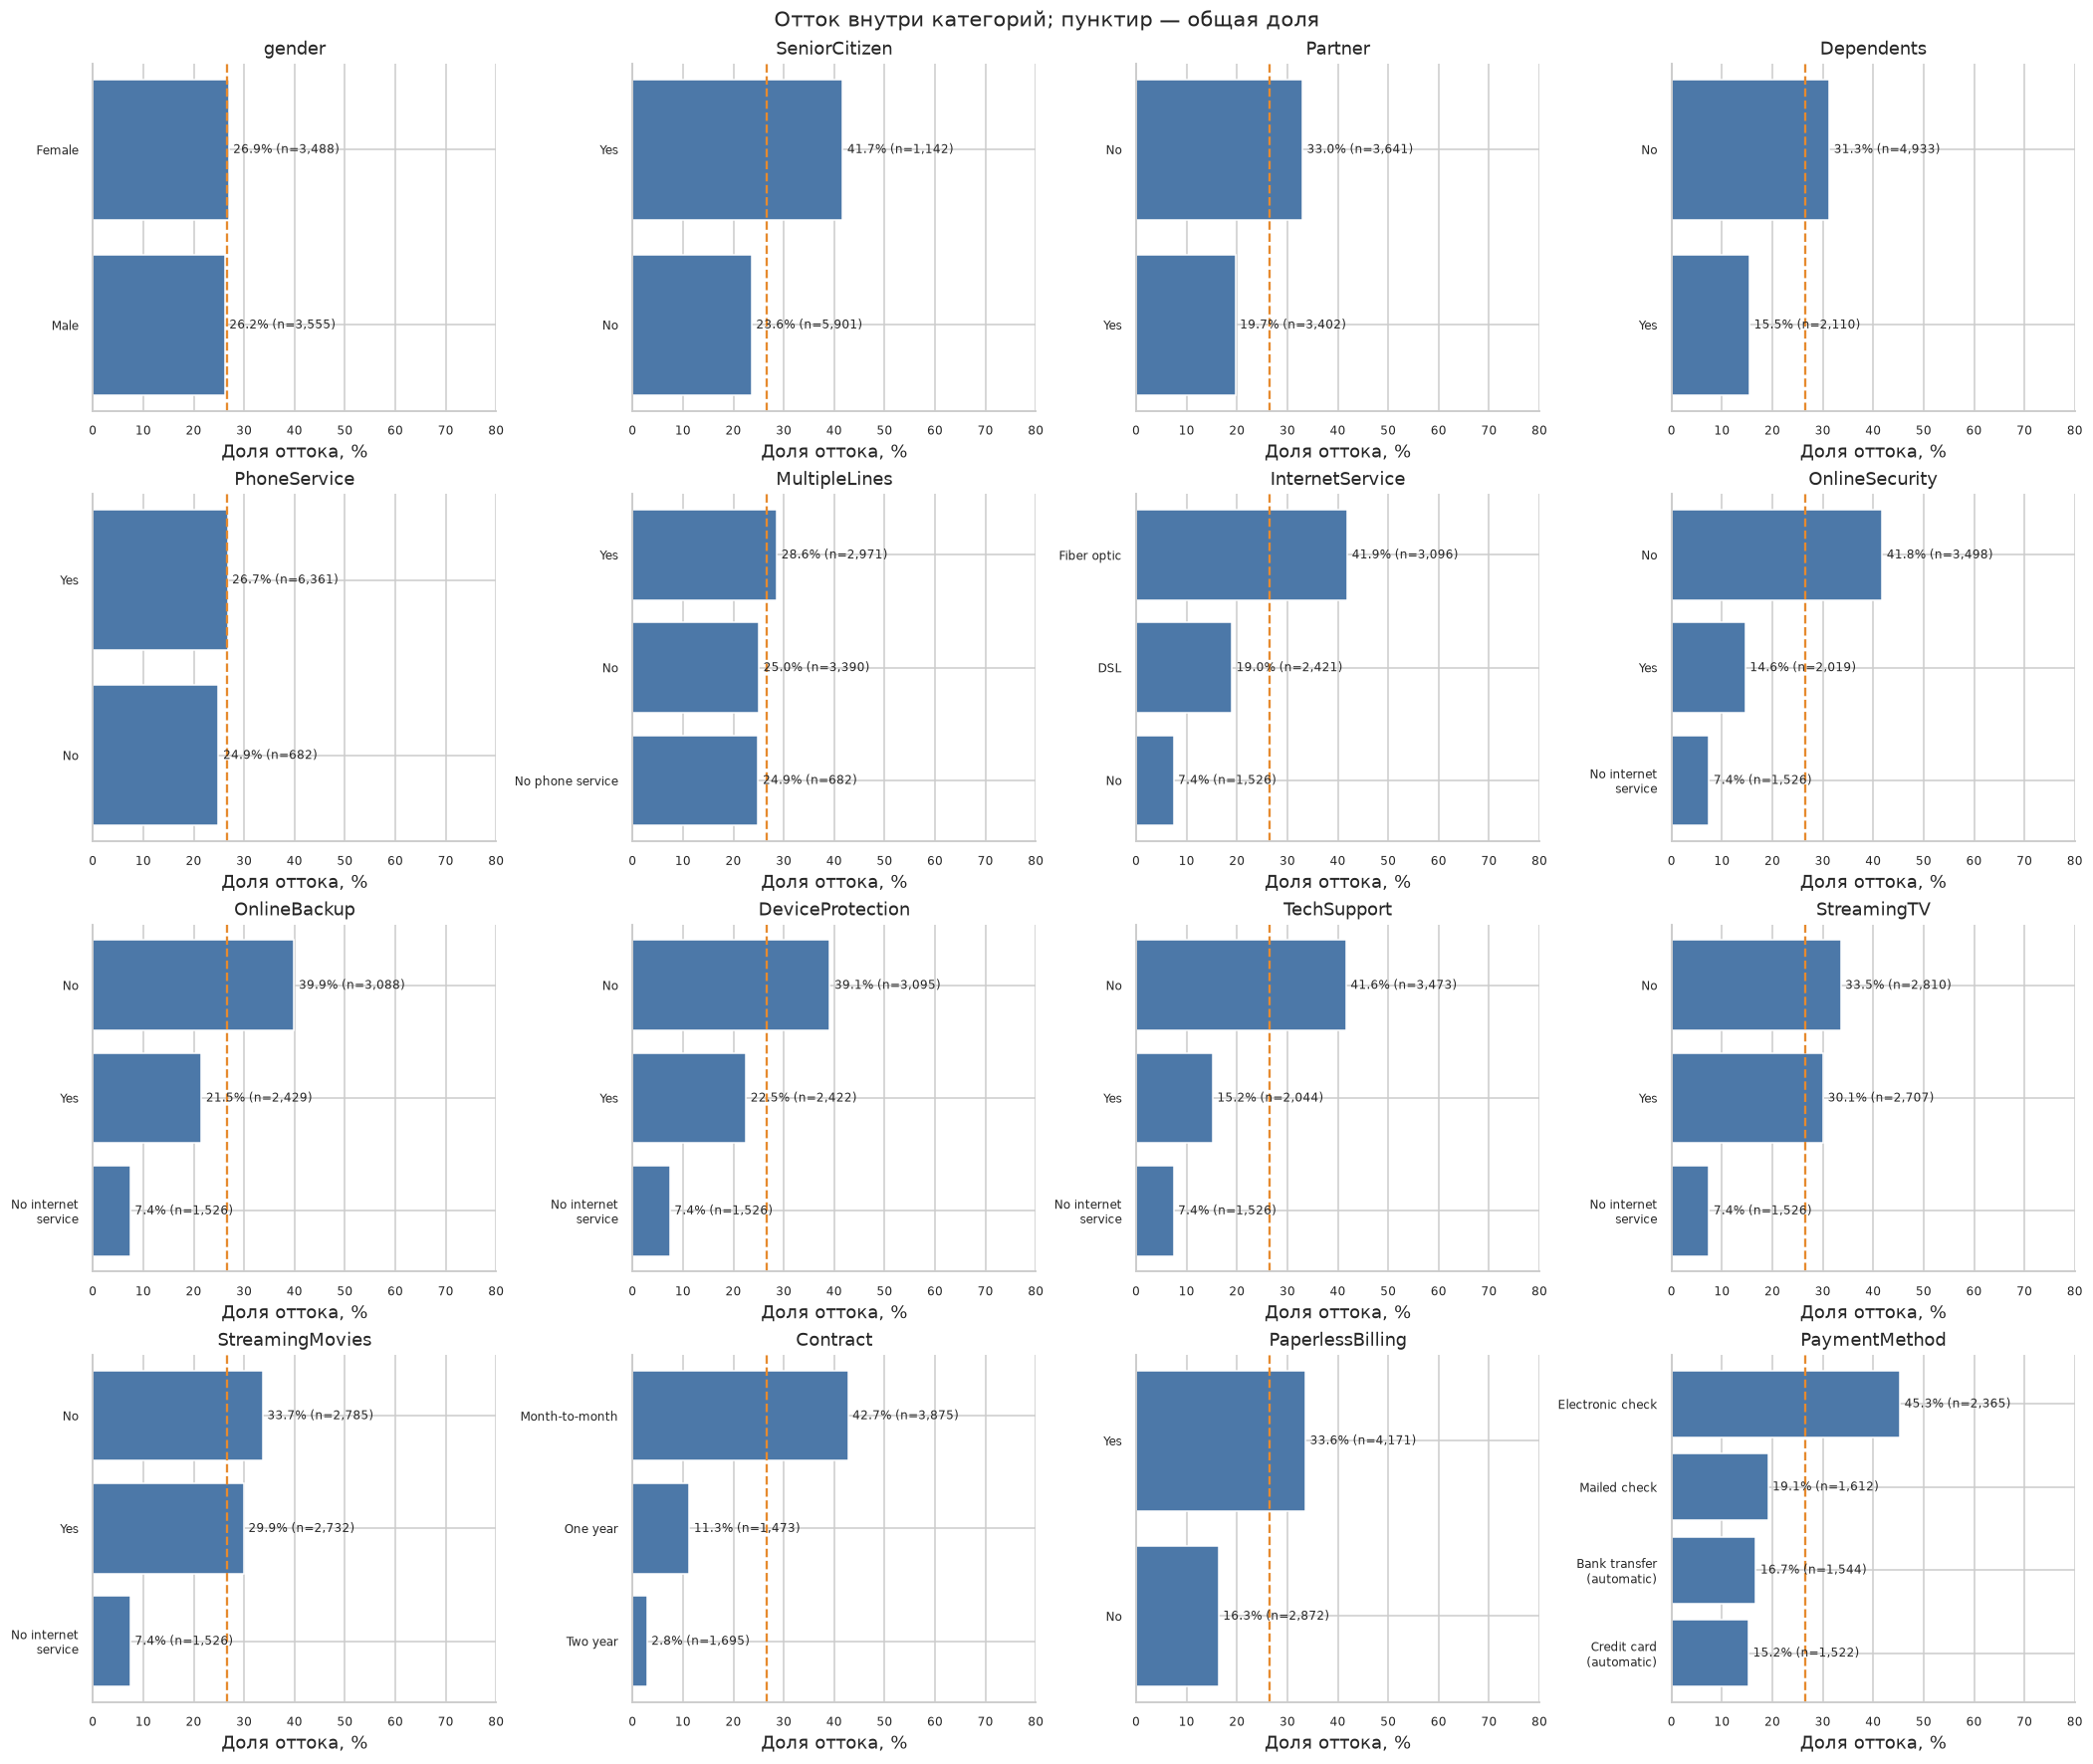

In [15]:
category_churn = {col: churn_summary(df, col) for col in categorical_cols}
fig, axes = plt.subplots(4, 4, figsize=(19, 16), layout="constrained")
for ax, col in zip(axes.flat, categorical_cols):
    table = category_churn[col].sort_values("churn_pct", ascending=False)
    positions = np.arange(len(table))
    bars = ax.barh(positions, table["churn_pct"], color=BLUE)
    ax.set_yticks(positions, [fill(str(label), 17) for label in table.index])
    ax.bar_label(bars, labels=[f"{r:.1f}% (n={n:,})" for r, n in zip(table["churn_pct"], table["n"])], padding=3, fontsize=8)
    ax.axvline(overall_churn_pct, color=ORANGE, linestyle="--")
    ax.invert_yaxis()
    ax.set(title=col, xlabel="Доля оттока, %", xlim=(0, 80))
    ax.tick_params(labelsize=8)
fig.suptitle("Отток внутри категорий; пунктир — общая доля", fontsize=14)
plt.show()

Помесячным договорам соответствует 42,71% оттока (1 655 / 3 875),
годовым — 11,27% (166 / 1 473), двухлетним — 2,83% (48 / 1 695).
У `Fiber optic` — 41,89% (1 297 / 3 096), у `DSL` — 18,96%
(459 / 2 421), без интернета — 7,40% (113 / 1 526).
У `Electronic check` — 45,29% (1 071 / 2 365).

Отток различается также по `TechSupport`, `OnlineSecurity`,
`SeniorCitizen`, `Partner`, `Dependents` и `PaperlessBilling`.
По полу различие невелико: 26,92% у женщин и 26,16% у мужчин.
Категория `No internet service` не объединялась с `No`.

Здесь нет оценки самостоятельного влияния признаков: группа без
поддержки может отличаться одновременно сроком, стоимостью и договором.
Поэтому формулировки «поддержка защищает» или «способ оплаты вызывает уход»
этим анализом не обоснованы.

## 6. Совместные факторы

### 6.1. Интернет и месячная плата

В разделе 5.1 мы увидели, что у ушедших клиентов медианная месячная плата выше. В разделе 5.3 обнаружили, что доля оттока различается и по типу подключения. Она составляет 41,89% у клиентов с оптоволоконным интернетом, 18,96% у клиентов с DSL и 7,40% у клиентов без интернета. Возникает вопрос. **Сопоставимы ли эти три группы по месячной плате?**

Проверим гипотезу, что группы с разным подключением отличаются и по сумме счёта. В `MonthlyCharges` записана общая месячная плата за услуги клиента. Для каждой категории `InternetService` посчитаем число абонентов (`n`), медианную плату (`median`) и границы средних 50% значений (`q25` и `q75`). Эти же границы показывают ящики на графике. Если группы заметно различаются по плате, это поможет осторожнее интерпретировать разницу в оттоке из 5.3.

,n,median,q25,q75
InternetService,,,,
DSL,2421,56.150,46.20,69.90
Fiber optic,3096,91.675,80.55,101.15
No,1526,20.150,19.70,20.90


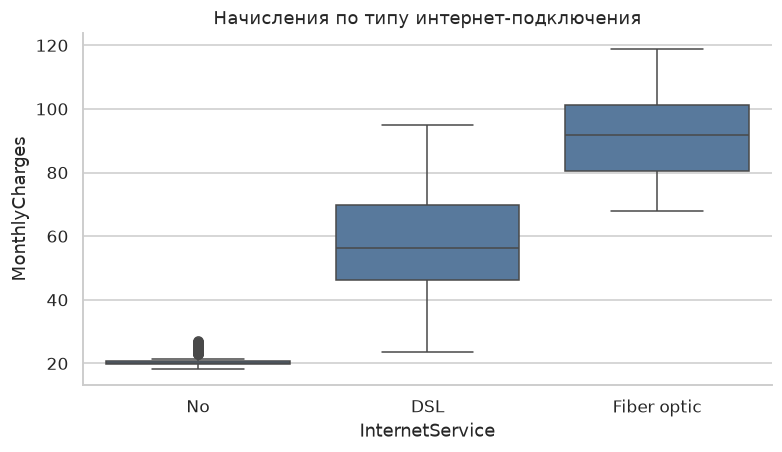

In [16]:
internet_price = df.groupby("InternetService")["MonthlyCharges"].agg(
    n="size", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)
)
display(internet_price.round(3))
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", order=["No", "DSL", "Fiber optic"], color=BLUE, ax=ax)
ax.set(title="Начисления по типу интернет-подключения", xlabel="InternetService", ylabel="MonthlyCharges")
plt.show()

Группы заметно различаются по месячной плате. Медиана составляет **20,15** у клиентов без интернета, **56,15** у клиентов с DSL и **91,675** у клиентов с оптоволоконным интернетом. У DSL средние 50% значений укладываются примерно в диапазон 46–70, а у оптоволоконного интернета — 81–101.
У группы с оптоволоконным интернетом в этой выборке одновременно выше и месячная плата, и доля оттока. Поэтому сравнение только по типу подключения включает и различия в сумме счёта.

### 6.2. Способ оплаты внутри типа договора

Сначала смотрим состав групп оплаты, затем их отток при одинаковом
типе договора. На тепловой карте каждая ячейка содержит долю и размер
своей группы; это не сравнение абсолютного числа ушедших.

,n,tenure_median,monthly_median,month_to_month_pct
PaymentMethod,,,,
Electronic check,2365,18.0,80.55,78.22
Mailed check,1612,15.0,34.70,55.40
Bank transfer (automatic),1544,48.0,73.10,38.15
Credit card (automatic),1522,47.0,73.03,35.68


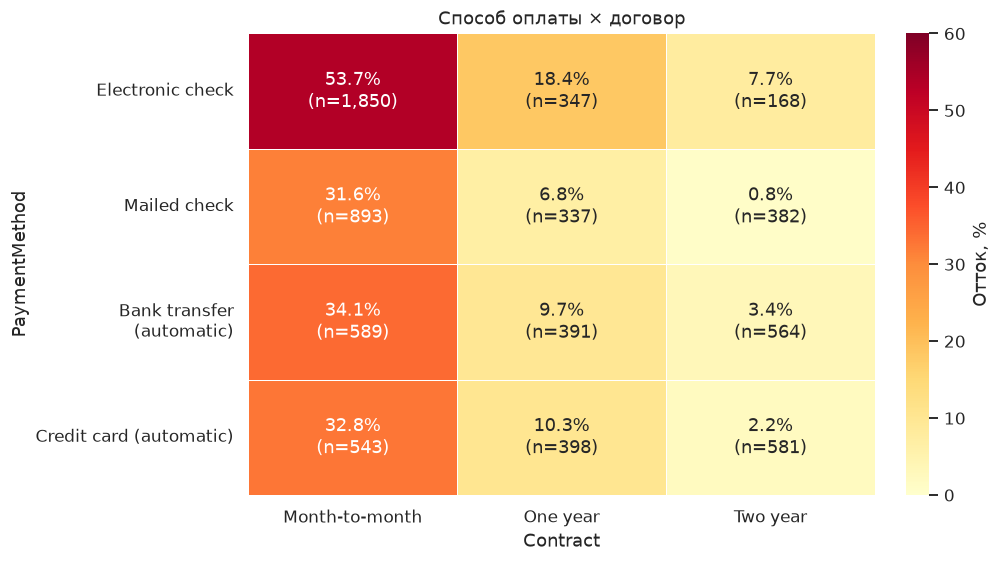

In [17]:
payment_profile = df.groupby("PaymentMethod").agg(
    n=("Churn", "size"), tenure_median=("tenure", "median"),
    monthly_median=("MonthlyCharges", "median"),
    month_to_month_pct=("Contract", lambda s: s.eq("Month-to-month").mean() * 100),
).reindex(PAYMENT_ORDER)
display(payment_profile.round(2))


def joint_churn_heatmap(table, row_order, col_order, ax, title):
    rates = table["churn_pct"].unstack().reindex(index=row_order, columns=col_order)
    sizes = table["n"].unstack().reindex(index=row_order, columns=col_order)
    annotations = pd.DataFrame("", index=rates.index, columns=rates.columns)
    for row in rates.index:
        for col in rates.columns:
            if pd.notna(rates.loc[row, col]):
                n = int(sizes.loc[row, col])
                small = " *" if n < 100 else ""
                annotations.loc[row, col] = f"{rates.loc[row, col]:.1f}%\n(n={n:,}){small}"
    sns.heatmap(rates, annot=annotations, fmt="", vmin=0, vmax=60, cmap="YlOrRd",
                linewidths=.5, cbar_kws={"label": "Отток, %"}, ax=ax)
    ax.set_title(title)
    ax.set_yticklabels([fill(str(label), 24) for label in rates.index], rotation=0)
    ax.set_xticklabels(rates.columns, rotation=0)


payment_contract = churn_summary(df, ["PaymentMethod", "Contract"])
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
joint_churn_heatmap(payment_contract, PAYMENT_ORDER, CONTRACT_ORDER, ax, "Способ оплаты × договор")
ax.set(xlabel="Contract", ylabel="PaymentMethod")
plt.show()

Среди клиентов `Electronic check` помесячные договоры имеют 78,22%,
медианный срок обслуживания — 18 месяцев, месячная плата — 80,55.
У `Mailed check` медианный срок ещё меньше (15 месяцев), но плата
ниже — 34,70: одного срока для описания различий недостаточно.

Внутри каждого типа договора у `Electronic check` доля оттока выше,
чем у остальных способов: 53,73% (994 / 1 850) на помесячном,
18,44% (64 / 347) на годовом и 7,74% (13 / 168) на двухлетнем.
Тип договора не объясняет всю наблюдаемую разницу. Но это ещё
не независимый эффект оплаты: другие характеристики не уравнены.
Небольшое число уходов в отдельных ячейках, например 3 из 382
для `Two year + Mailed check`, ограничивает точность процентов.

### 6.3. Тип договора при сопоставимом сроке обслуживания

Сравниваем договоры внутри тех же интервалов `tenure`.
Звёздочкой отмечены группы меньше 100 клиентов: отсутствие событий
в небольшой группе не означает нулевого риска.

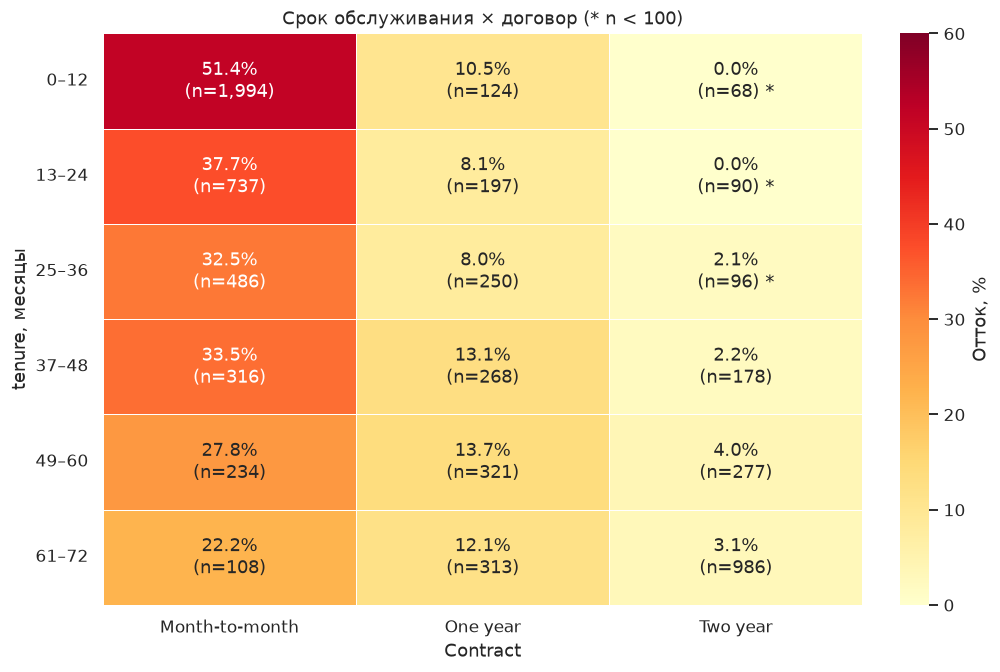

In [18]:
tenure_contract = churn_summary(segments, ["tenure_group", "Contract"])
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
joint_churn_heatmap(tenure_contract, segments["tenure_group"].cat.categories, CONTRACT_ORDER,
                    ax, "Срок обслуживания × договор (* n < 100)")
ax.set(xlabel="Contract", ylabel="tenure, месяцы")
plt.show()

Во всех шести интервалах `tenure` доля оттока максимальна у
помесячных и минимальна у двухлетних договоров. Наблюдаемая
разница не исчезает при таком приближённом учёте срока обслуживания.

В первых двух интервалах у двухлетних договоров нет уходов,
но группы содержат только 68 и 90 клиентов. Их фактический риск
не установлен равным нулю. Разбиение на интервалы не заменяет
совместную модель и не устанавливает причинное влияние договора.

## 7. Связи между признаками

### 7.1. Pearson и Spearman

Pearson описывает линейную, Spearman — монотонную связь.
Пропуски исключаются только для соответствующей пары:
с `TotalCharges` доступно 7 032 наблюдения, без него — 7 043.

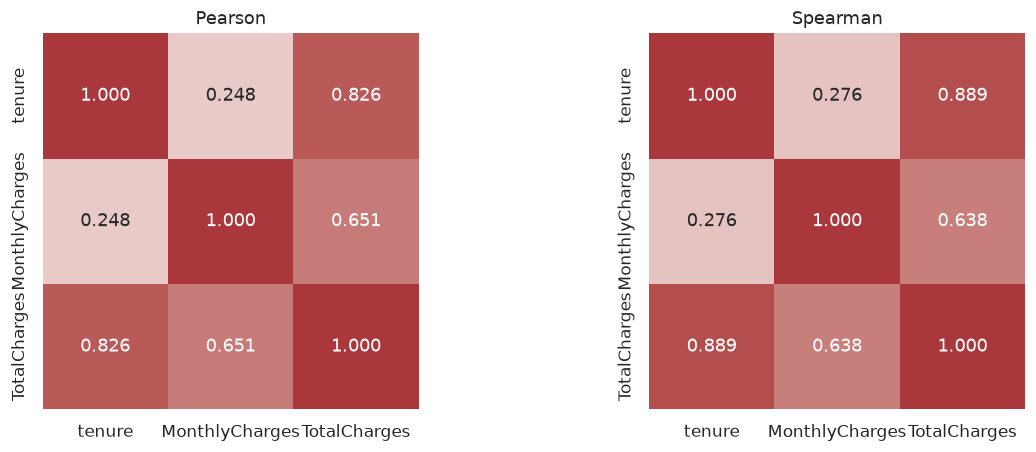

In [19]:
pearson = df[NUMERIC].corr(method="pearson")
spearman = df[NUMERIC].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, matrix, title in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    sns.heatmap(matrix, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(title)
plt.show()

У `tenure` и `TotalCharges` Pearson ≈ 0,826, Spearman ≈ 0,889.
У `MonthlyCharges` и `TotalCharges` — соответственно ≈ 0,651 и ≈ 0,638.
Начисления и срок связаны, что может затруднять интерпретацию
коэффициентов линейной модели. Но высокая парная корреляция сама
по себе не показывает, что один признак бесполезен. Проверка
состава признаков и регуляризации относится к этапу моделирования.

### 7.2. φk для смешанных типов

Числовыми явно объявлены только `tenure`, `MonthlyCharges`, `TotalCharges`;
для них заданы 10 равных по ширине интервалов. `SeniorCitizen`
обрабатывается как категория. `customerID` исключён.

φk находится в диапазоне 0–1 и не показывает направление связи.
Он зависит в том числе от разбиения числовых значений. Строковые
названия `Contract` не объявляют автоматически порядок договоров.
Попарная связь с целью не равна важности признака в модели.
Подробности параметров — в [документации phik](https://phik.readthedocs.io/en/latest/phik.html#phik.phik.phik_matrix).

`NaN` не заполняются: при `dropna=True` пропуски исключаются из
соответствующих пар, а не из всей таблицы.

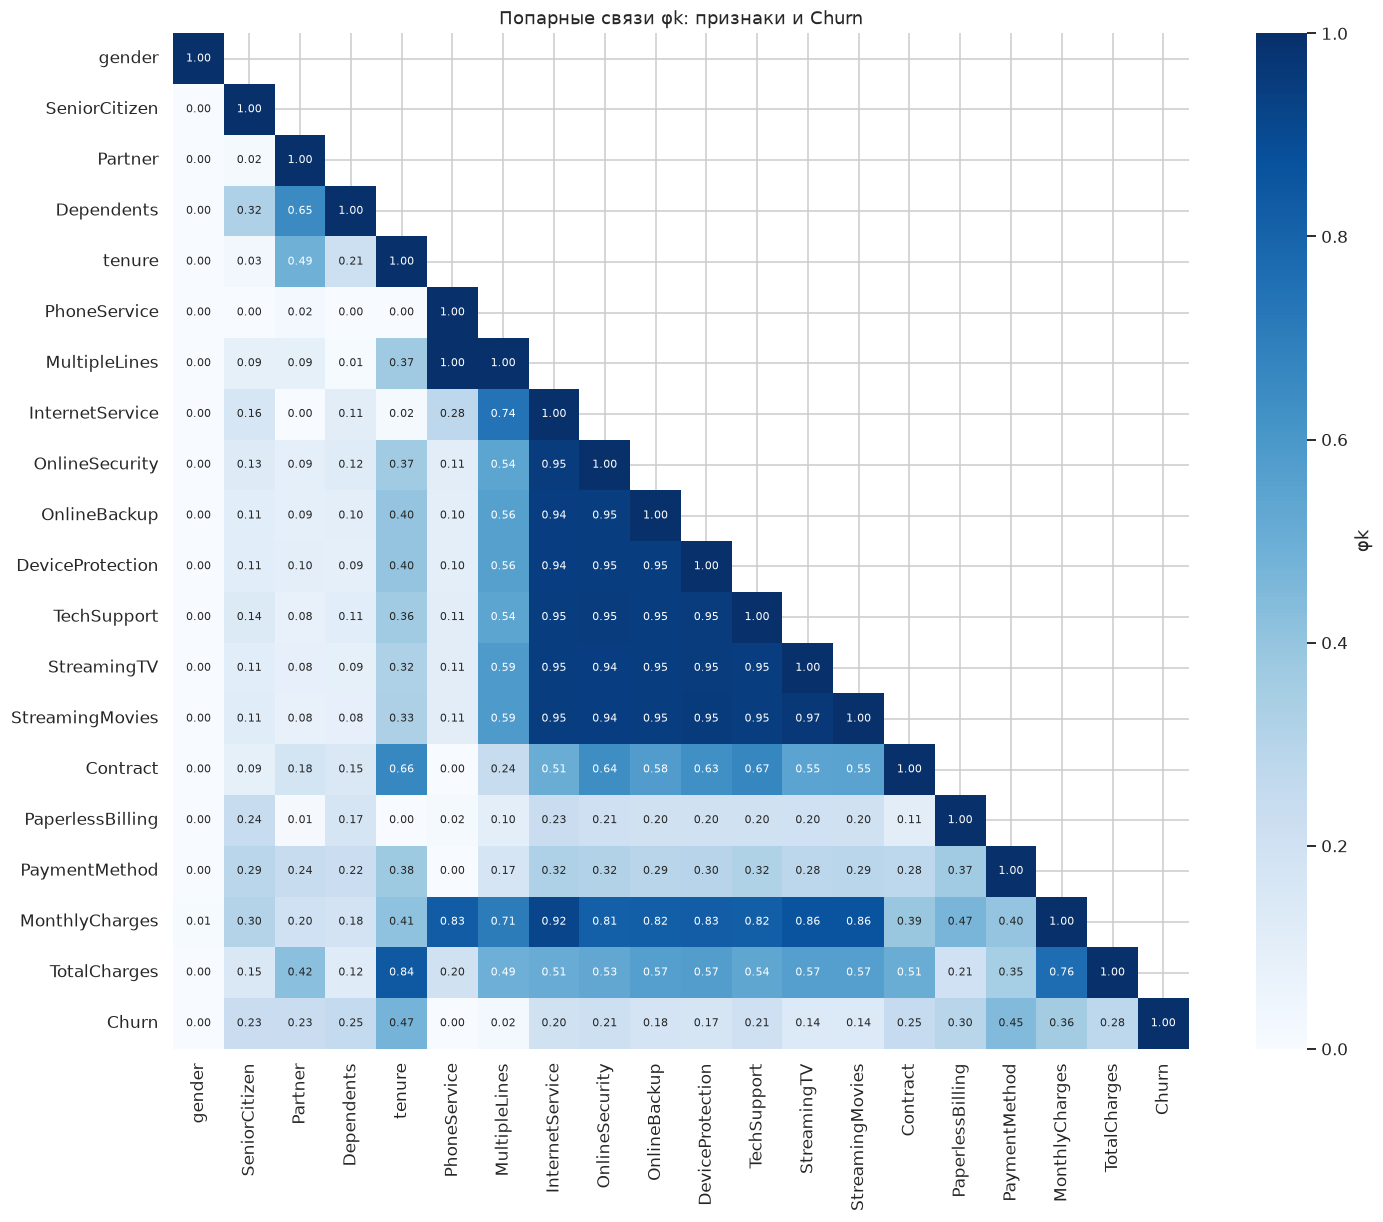

,phi_k_with_Churn
tenure,0.474
PaymentMethod,0.449
MonthlyCharges,0.360
PaperlessBilling,0.296
TotalCharges,0.281
Dependents,0.254
Contract,0.252
SeniorCitizen,0.233


In [20]:
phik_matrix = df.drop(columns="customerID").phik_matrix(
    interval_cols=NUMERIC, bins=10, quantile=False, dropna=True, njobs=1,
)
mask = np.triu(np.ones(phik_matrix.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11), layout="constrained")
sns.heatmap(phik_matrix, mask=mask, vmin=0, vmax=1, cmap="Blues",
            annot=True, fmt=".2f", annot_kws={"fontsize": 7}, square=True,
            cbar_kws={"label": "φk"}, ax=ax)
ax.set_title("Попарные связи φk: признаки и Churn")
plt.show()
display(phik_matrix["Churn"].drop("Churn").sort_values(ascending=False).head(8).to_frame("phi_k_with_Churn").round(3))

Наибольшие рассчитанные связи с `Churn` — у `tenure` (≈ 0,47),
`PaymentMethod` (≈ 0,45) и `MonthlyCharges` (≈ 0,36).
Сильные связи между самими признаками включают `tenure`–`TotalCharges`
(≈ 0,84), `Contract`–`tenure` (≈ 0,66) и зависимости основных
и дополнительных интернет-услуг.

Коэффициент `Contract`–`Churn` здесь около 0,25, хотя доли оттока
по договорам сильно различаются. Матрица дополняет группировки,
а не заменяет их. Низкий либо высокий φk не является достаточным
основанием для удаления признака или утверждения о причине ухода.

## 8. Итоги и передача в моделирование

В таблице приведены наблюдения, варианты подготовки и проверяемые
гипотезы. Модельные эксперименты, выполненные в этой работе, описаны в разделах 10–16.
Основания находятся в соответствующих разделах выше.

| Наблюдение | Подготовка данных / статус | Что проверить в модели |
|---|---|---|
| 11 неизвестных `TotalCharges`, все при `tenure = 0` | В EDA оставлены `NaN`; при построении модели подставляем ноль только при нулевом стаже | Сравнение с вариантом без TotalCharges |
| Полных дублей и повторных ID нет; у разных клиентов есть одинаковые профили | Строки сохранены; `customerID` исключается из признаков | Ограничения предсказуемости при одинаковых наблюдаемых характеристиках и разных исходах |
| Отток 26,54%; Accuracy постоянного прогноза 73,46% | В моделировании основная метрика — ROC-AUC | Веса, сэмплирование и порог; качество и калибровка вероятностей |
| По сроку доля оттока снижается, по месячной плате немонотонна | Исходные числовые признаки сохранены; интервалы используются только для EDA | Логарифм стажа и сочетание короткого стажа с помесячным договором |
| По договорам различия сохраняются внутри интервалов срока | Категории договора сохранены | Дополнительная полезность `Contract` с учётом срока |
| `Electronic check` отличается и внутри каждого типа договора | Способ оплаты сохранён как категория | Совместная полезность оплаты, договора, срока и стоимости |
| Интернет связан одновременно со стоимостью и оттоком | Основные и дополнительные услуги сохранены раздельно | Какие связи сохраняются при совместном учёте признаков |
| Специальные категории услуг повторяют отсутствие основной услуги | В EDA не объединены с `No`; в модели получают отдельные индикаторы | Варианты кодирования и избыточность, без потери смысла категорий |
| Накопленные начисления связаны со сроком и текущей платой | Нет автоматического удаления строк или коррелирующих столбцов | Полезность `TotalCharges` дополнительно к сроку и плате; регуляризация |
| Распределения групп перекрываются, есть маленькие подгруппы | Проценты сопровождаются `n` | Устойчивость качества и выводов на валидации |

### Ограничения

- Это снимок данных одного набора, а не продольная история клиентов.
  Связь срока с оттоком не является оценкой индивидуального риска по времени.
- Нет истории изменения тарифов, отдельных платежей и причин ухода.
  Наблюдаемые ассоциации не устанавливают причинность.
- Совместные группировки учитывают только часть признаков; остаются
  различия состава групп. Небольшие группы ограничивают точность долей.
- При подготовке модели разбиение выполняется до обучения преобразований.
  Ноль при пропуске начислений и нулевом стаже подставляем по фиксированному правилу.
  Средние, масштабы и категории для кодирования определяем по обучающей части каждого раунда.
  Модели и гиперпараметры сравниваем по валидационным прогнозам на данных разработки.
- EDA изучает весь доступный набор: будущая тестовая часть уже участвовала
  в описательном анализе. Оценка на ней не является полностью независимой
  проверкой всех исследовательских решений; учитываем это при интерпретации итоговых метрик.

## 9. Контроль выполнения

Проверяем сохранение исходных строк и пропусков, полноту группировок
и корректность рассчитанных матриц. Это проверки результата данного EDA,
а не обучение или оценка модели.

In [21]:
assert df.shape == raw.shape == (7043, 21)
assert df["customerID"].equals(raw["customerID"])
converted = ["SeniorCitizen", "TotalCharges"]
pd.testing.assert_frame_equal(df.drop(columns=converted), raw.drop(columns=converted))
assert df["TotalCharges"].isna().equals(missing_total)
assert int(df["TotalCharges"].isna().sum()) == 11
assert int(df["Churn"].eq("Yes").sum()) == 1869
assert int(tenure_summary["n"].sum()) == int(charges_summary["n"].sum()) == len(df)
assert int(payment_contract["n"].sum()) == int(tenure_contract["n"].sum()) == len(df)
assert all(int(table["n"].sum()) == len(df) for table in category_churn.values())
assert service_checks[["absent_main_wrong_status_n", "present_main_special_status_n"]].eq(0).all().all()
assert phik_matrix.index.equals(phik_matrix.columns)
assert np.allclose(phik_matrix, phik_matrix.T, equal_nan=True)
assert np.isfinite(phik_matrix.to_numpy()).all()
assert phik_matrix.ge(0).all().all() and phik_matrix.le(1).all().all()
print("Проверки пройдены: все 7043 клиента сохранены, 11 NaN сохранены, группировки полны.")

Проверки пройдены: все 7043 клиента сохранены, 11 NaN сохранены, группировки полны.


## 10. От клиента к прогнозу

Оператору нужны два результата. Для каждого абонента оценим вероятность `Churn = Yes`. Для группы клиентов выясним, какие наблюдаемые характеристики связаны с повышенным риском. Одна строка описывает одного абонента. В качестве первой модели возьмём логистическую регрессию — она возвращает число от 0 до 1 и позволяет интерпретировать коэффициенты.

### 10.1. Какие данные видит модель

Ответ кодируем как 1 для ушедшего и 0 для оставшегося клиента. Сохраним `customerID` в индексе, чтобы позже вернуть прогноз нужному человеку. Отложим 20% клиентов для итоговой проверки. Стратификация сохраняет примерно одинаковую долю уходов в обеих частях.

In [22]:
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
# Для модели используем исходные поля и числовую версию TotalCharges из EDA.
clients = raw.assign(TotalCharges=df["TotalCharges"]).set_index("customerID")
assert clients.index.is_unique
X = clients.drop(columns="Churn")
y = clients["Churn"].map({"No": 0, "Yes": 1})
assert y.notna().all() and {"customerID", "Churn"}.isdisjoint(X.columns)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
assert (len(X_train), len(X_test)) == (5634, 1409)
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
outer_splits = list(cv.split(X_train, y_train))
print(f"Разработка и валидация — {len(X_train):,} клиентов. Итоговый тест — {len(X_test):,}.")

Разработка и валидация — 5,634 клиентов. Итоговый тест — 1,409.


### 10.2. Подготовка признаков и инструменты экспериментов

**Что делает эта ячейка.** Функция `prepare_features` получает таблицу с признаками, создаёт её копию и готовит вход для модели. В EDA мы нашли 11 пропусков в `TotalCharges` у абонентов с нулевым стажем. Для модели подставляем 0 только при сочетании этих двух условий. Это допущение о начислениях в начале обслуживания. В базовом варианте остальные признаки сохраняем. Здесь же задаём варианты с новыми признаками и без `TotalCharges`, которые по отдельности проверим в разделе 13.

**Зачем `imbalanced-learn`.** В исходной выборке ушли около 27% абонентов. При таком соотношении полезно проверить, лучше ли модель обнаруживает отток, когда получает примерно поровну примеров обоих классов. Библиотеку устанавливаем как `imbalanced-learn`, а импортируем как `imblearn`.

Для этих экспериментов в следующем пункте соберём `Pipeline` из `imblearn`. Он меняет состав примеров только при обучении внутри каждого раунда. На проверочных данных сохраняются исходные клиенты и доли классов. У базовой модели шаг балансировки пропускается.

In [23]:
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

def prepare_features(frame, feature="original"):
    prepared = frame.copy()
    at_start = prepared["tenure"].eq(0) & prepared["TotalCharges"].isna()
    prepared.loc[at_start, "TotalCharges"] = 0
    if feature == "log_tenure":
        prepared["log_tenure"] = np.log1p(prepared["tenure"])
    elif feature == "early_monthly":
        prepared["early_monthly"] = (
            prepared["Contract"].eq("Month-to-month") & prepared["tenure"].le(12)
        ).astype(int)
    elif feature == "without_total":
        prepared = prepared.drop(columns="TotalCharges")
    return prepared

### 10.3. Собираем базовую модель

Baseline — первая рабочая конфигурация, с которой будем сравнивать другие варианты. Начнём с логистической регрессии на исходном наборе признаков. Чтобы при обучении и прогнозировании одинаково подготовить данные клиента, соберём все действия в один `Pipeline`.

#### Какие шаги проходит клиент

| Шаг в коде | Что происходит и зачем                                                                                                                                                                                            |
|---|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| `features` | Вызываем `prepare_features` из пункта 10.2. В baseline эта функция заполняет пропуск в `TotalCharges` нулём при нулевом стаже.                                                                                    |
| `preparation` | `ColumnTransformer` направляет числовые и категориальные столбцы в разные преобразования. Числовые признаки `tenure`, `MonthlyCharges` и `TotalCharges` идут в `StandardScaler`. Категории идут в `OneHotEncoder`. |
| `sampling` | В baseline стоит `passthrough`, то есть этот шаг пропускается.                    |
| `model` | Логистическая регрессия учится по подготовленным признакам оценивать вероятность ухода.                                                                                                                           |

`StandardScaler` вычитает среднее по числовому столбцу и делит на стандартное отклонение. Например, значение на одно стандартное отклонение выше среднего превращается в 1. Масштабирование полезно здесь, потому что L2-регуляризация штрафует большие коэффициенты, а стаж и начисления измеряются в разных единицах.

Для категорий `OneHotEncoder` создаёт индикаторы 0 и 1. Например, у абонента с помесячным договором индикатор `Contract_Month-to-month` равен 1, а индикаторы годового и двухлетнего договоров — 0. `SeniorCitizen` тоже в этом списке, поскольку исходные 0 и 1 обозначают две категории.

#### Как задаём конфигурацию

Функция `make_pipeline` собирает эти шаги. Её аргументы дают возможность позже поменять конкретный элемент, например шкалу или способ балансировки, и оставить остальные настройки для сравнения.

In [24]:
categorical_features = X_train.columns.drop(NUMERIC).tolist()

def make_pipeline(*, scale="standard", balance="ordinary", feature="original", family="logistic"):
    numeric = list(NUMERIC)
    if feature == "without_total":
        numeric.remove("TotalCharges")
    elif feature in ("log_tenure", "early_monthly"):
        numeric.append(feature)

    scalers = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}
    preparation = ColumnTransformer([
        ("numeric", scalers[scale], numeric),
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])
    samplers = {
        "ordinary": "passthrough", "weights": "passthrough",
        "under": RandomUnderSampler(random_state=SEED),
        "over": RandomOverSampler(random_state=SEED),
    }
    if family == "tree":
        model = DecisionTreeClassifier(random_state=SEED)
    else:
        model = LogisticRegression(
            C=1.0, solver="newton-cholesky", max_iter=1000,
            class_weight="balanced" if balance == "weights" else None,
            random_state=SEED,
        )
    return Pipeline([
        ("features", FunctionTransformer(prepare_features, kw_args={"feature": feature})),
        ("preparation", preparation), ("sampling", samplers[balance]), ("model", model),
    ])

#### Создаём базовую модель

Вызываем `make_pipeline()` с настройками по умолчанию. Получаем логистическую регрессию с `StandardScaler`, исходными признаками и исходной долей классов. Эта строка задаёт конфигурацию модели.

In [25]:
baseline = make_pipeline()

### 10.4. Как сравниваем модели и выбираем порог

**Как сравниваем модели**

- **ROC-AUC — основная метрика.** Оператору важно поставить клиентов с высоким риском первыми в списке. ROC-AUC оценивает, как часто модель даёт ушедшему клиенту более высокий риск, чем оставшемуся. Для такого сравнения общий порог не требуется.
- **Оценка Брайера.** По условию кейса для каждого клиента нужна оценка вероятности. Брайер измеряет средний квадрат разницы между этой вероятностью и фактическим исходом 0 или 1. Чем меньше значение, тем точнее оценки.

**Как оцениваем список предупреждений**

- **Precision** нужна, чтобы оценить, сколько сигналов подтвердится. Это доля действительно ушедших среди клиентов с предупреждением.
- **Recall** нужна, чтобы оценить, сколько уходов мы замечаем. Это доля клиентов с предупреждением среди всех действительно ушедших.

При неизвестной стоимости ошибок выбираем порог по **индексу Юдена**. Максимизируем разность между долей обнаруженных уходов и долей ложных тревог среди оставшихся. При равных значениях выбираем больший конечный порог.

**Как защищаемся от утечки данных.** При каждом обучении средние и стандартные отклонения для масштабирования, список категорий для кодирования и коэффициенты модели вычисляются только по обучающей части этого раунда. К проверочной части применяется уже обученная подготовка. Пересэмплирование выполняется только при обучении. Итоговые 1 409 клиентов используются для оценки после фиксации модели и порога.

In [26]:
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.metrics import (brier_score_loss, confusion_matrix, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_predict

def youden_threshold(truth, risk):
    fpr, tpr, thresholds = roc_curve(truth, risk, drop_intermediate=False)
    finite = np.isfinite(thresholds)
    return float(thresholds[finite][np.argmax(np.round((tpr - fpr)[finite], 12))])

# На небольших матрицах достаточно одного вычислительного потока.
@threadpool_limits.wrap(limits=1)
def evaluate(name, pipeline, search=None, *, summarize_coefficients=False):
    records, coefficients, chosen_params = [], [], []
    oof = pd.Series(np.nan, index=X_train.index, name="risk")
    for fold, (learning, validation) in enumerate(outer_splits, start=1):
        X_fit, y_fit = X_train.iloc[learning], y_train.iloc[learning]
        X_val, y_val = X_train.iloc[validation], y_train.iloc[validation]
        model = clone(pipeline)
        if search is not None:
            params = search(model, X_fit, y_fit)
            model.set_params(**params)
            chosen_params.append(params)

        # Внутренние прогнозы нужны только для выбора порога этого раунда.
        inner_risk = cross_val_predict(model, X_fit, y_fit, cv=inner_cv, method="predict_proba")[:, 1]
        threshold = youden_threshold(y_fit, inner_risk)
        model.fit(X_fit, y_fit)
        risk = model.predict_proba(X_val)[:, 1]
        assert oof.loc[X_val.index].isna().all() and list(model.classes_) == [0, 1]
        oof.loc[X_val.index] = risk
        record = {"Раунд": fold, "ROC-AUC": roc_auc_score(y_val, risk),
                  "Брайер": brier_score_loss(y_val, risk), "Порог J": threshold}
        for label, cutoff in [("0,50", 0.50), ("J", threshold)]:
            alerts = risk >= cutoff
            record[f"Precision {label}"] = precision_score(y_val, alerts, zero_division=0)
            record[f"Recall {label}"] = recall_score(y_val, alerts)
        records.append(record)

        if summarize_coefficients:
            beta = model["model"].coef_[0]
            # Выражаем 12 исходных месяцев в единицах шкалы, на которой обучена регрессия.
            scale_step = model["preparation"].named_transformers_["numeric"]
            step = 12.0
            if isinstance(scale_step, StandardScaler):
                step = 12 / scale_step.scale_[0]
            elif isinstance(scale_step, MinMaxScaler):
                step = 12 * scale_step.scale_[0]
            coefficients.append({"Число весов": len(beta), "Макс. |вес|": abs(beta).max(),
                                 "Медиана |вес|": np.median(abs(beta)),
                                 "Множитель шансов за 12 мес.": np.exp(beta[0] * step)})
    assert oof.index.equals(y_train.index) and oof.between(0, 1).all()
    return {"name": name, "pipeline": pipeline, "search": search, "risk": oof,
            "scores": pd.DataFrame(records).set_index("Раунд"),
            "coefficients": pd.DataFrame(coefficients), "params": chosen_params}

def score_table(runs, columns):
    """Среднее ± выборочное стандартное отклонение по пяти внешним раундам."""
    table = {}
    for run in runs:
        scores = run["scores"][columns]
        table[run["name"]] = [f"{scores[c].mean():.4f} ± {scores[c].std():.4f}" for c in columns]
    return pd.DataFrame.from_dict(table, orient="index", columns=columns)

base = evaluate("Логрегрессия · базовая", baseline, summarize_coefficients=True)
metrics = ["ROC-AUC", "Брайер", "Precision 0,50", "Recall 0,50"]
display(score_table([base], metrics))

,ROC-AUC,Брайер,"Precision 0,50","Recall 0,50"
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.6529 ± 0.0285,0.5431 ± 0.0460


Базовая модель дала ROC-AUC 0,8462 и оценку Брайера 0,1351. При пороге 0,50 из 100 предупреждений верны примерно 65, а из 100 действительно ушедших обнаружены примерно 54. Это средние результаты на пяти проверочных группах.

### 10.5. Что меняется при другом пороге

В 10.4 мы получили оценки вероятности ухода. Теперь нужно решить, кого включить в список предупреждений. В список попадают клиенты с оценкой, равной порогу или выше. Например, при риске **0,34** клиент попадёт в список с порогом **0,281**. С порогом **0,50** предупреждение получат только клиенты с более высокими оценками. Проверим, сколько дополнительных уходов замечаем при снижении порога и как меняется доля верных предупреждений.

**Слева** — Precision и Recall при разных порогах. При движении влево порог снижается и список расширяется. В него могут попасть как дополнительные ушедшие, так и оставшиеся клиенты. Серая линия отмечает исходный порог 0,50, чёрная — порог по индексу Юдена.

**Справа** — ROC-кривая. Каждая точка соответствует порогу. По вертикали читаем долю обнаруженных уходов, по горизонтали — долю ложных тревог среди оставшихся. Индекс Юдена — разность этих двух долей. Оранжевая точка отмечает порог, при котором эта разность максимальна.

**Как связаны порог на графике и метрики в таблице.** Для графиков объединяем проверочные прогнозы пяти раундов разработки. Так получаем одну кривую и один порог для иллюстрации. В таблице `Precision J` и `Recall J` — средние по пяти раундам. В каждом раунде сначала выбираем свой порог на внутренних прогнозах, затем применяем его к внешней проверочной части.

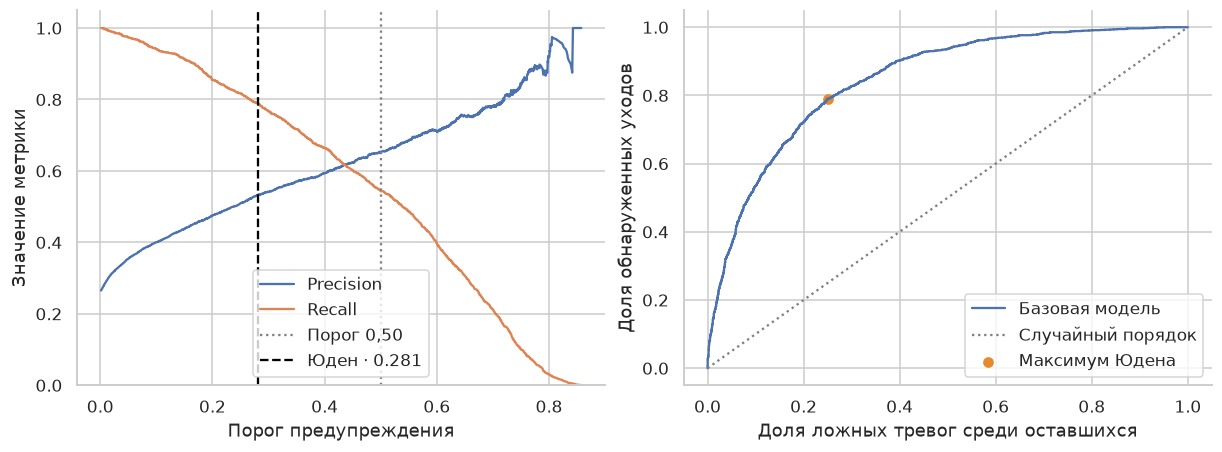

,"Precision 0,50","Recall 0,50",Precision J,Recall J
Логрегрессия · базовая,0.6529 ± 0.0285,0.5431 ± 0.0460,0.5356 ± 0.0203,0.7739 ± 0.0319


In [27]:
from sklearn.metrics import precision_recall_curve

base_risk = base["risk"]
base_cut = youden_threshold(y_train, base_risk)
precision, recall, cuts = precision_recall_curve(y_train, base_risk)
fpr, tpr, roc_cuts = roc_curve(y_train, base_risk, drop_intermediate=False)
point = np.flatnonzero(roc_cuts == base_cut)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(cuts, precision[:-1], label="Precision")
axes[0].plot(cuts, recall[:-1], label="Recall")
axes[0].axvline(0.50, color="grey", ls=":", label="Порог 0,50")
axes[0].axvline(base_cut, color="black", ls="--", label=f"Юден · {base_cut:.3f}")
axes[0].set(xlabel="Порог предупреждения", ylabel="Значение метрики", ylim=(0, 1.05))
axes[0].legend()
axes[1].plot(fpr, tpr, label="Базовая модель")
axes[1].plot([0, 1], [0, 1], color="grey", ls=":", label="Случайный порядок")
axes[1].scatter(fpr[point], tpr[point], color=ORANGE, label="Максимум Юдена")
axes[1].set(xlabel="Доля ложных тревог среди оставшихся", ylabel="Доля обнаруженных уходов")
axes[1].legend()
plt.show()
cut_metrics = ["Precision 0,50", "Recall 0,50", "Precision J", "Recall J"]
display(score_table([base], cut_metrics))

На общей ROC-кривой baseline максимум индекса Юдена соответствует порогу **0,281**. Таблица показывает, как правило выбора порога сработало в пяти проверочных раундах. Средний Recall вырос с **54,3% до 77,4%**, а Precision снизилась с **65,3% до 53,6%** по сравнению с порогом 0,50.
Для оператора это означает, что модель замечает примерно **77 из 100 ушедших** вместо 54. При этом подтверждается примерно **54 из 100 предупреждений** вместо 65. Эту же схему сравнения применим в разделе 12, когда проверим варианты с балансировкой классов.

### 10.6. Можно ли доверять значению вероятности

На графике калибровки делим клиентов по прогнозу на восемь примерно равных групп. Точка с координатами (0,30; 0,33) означала бы, что модель дала группе в среднем 30% риска, а ушли 33% её клиентов. Близость к диагонали показывает согласие прогноза с наблюдаемой частотой.

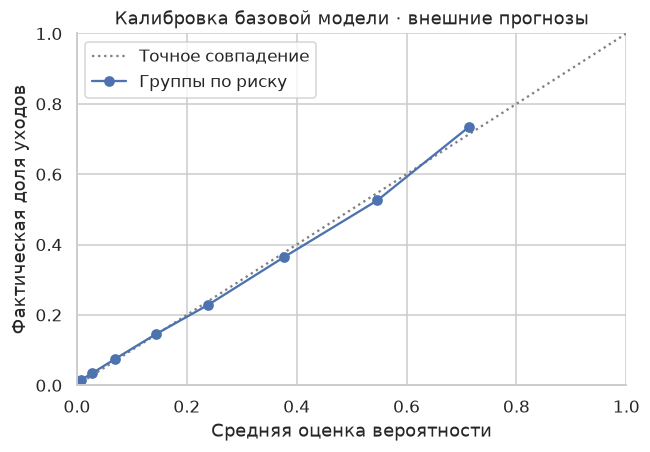

In [28]:
def calibration_plot(truth, risk, title):
    pairs = pd.DataFrame({"risk": np.asarray(risk), "churn": np.asarray(truth)})
    bins = pd.qcut(pairs["risk"], 8, duplicates="drop")
    groups = pairs.groupby(bins, observed=True).agg(
        forecast=("risk", "mean"), observed=("churn", "mean"), clients=("churn", "size"),
    )
    fig, ax = plt.subplots(figsize=(5.8, 4), layout="constrained")
    ax.plot([0, 1], [0, 1], ls=":", color="grey", label="Точное совпадение")
    ax.plot(groups["forecast"], groups["observed"], "o-", label="Группы по риску")
    ax.set(xlabel="Средняя оценка вероятности", ylabel="Фактическая доля уходов",
           xlim=(0, 1), ylim=(0, 1), title=title)
    ax.legend()
    plt.show()
    return groups.reset_index(drop=True)

base_cal = calibration_plot(y_train, base_risk, "Калибровка базовой модели · внешние прогнозы")

В группе самых высоких прогнозов из 705 клиентов средний прогноз составил 71,4%, фактическая доля ухода — 73,5%.

## 11. Масштабирование и коэффициенты

В базовой модели мы использовали `StandardScaler`. Теперь проверим, даёт ли масштабирование преимущество нашей логистической регрессии. Один год и двенадцать месяцев описывают один и тот же стаж. При этом L2-регуляризация штрафует большие коэффициенты. Чтобы получить одинаковый вклад стажа в формулу, коэффициент при измерении в годах должен быть в 12 раз больше коэффициента при измерении в месяцах. Поэтому смена шкалы может изменить результат обучения при одном и том же значении `C`.

Сравним три способа подготовки числовых полей.

- **Без масштабирования.** Стаж остаётся в месяцах, начисления — в исходных денежных единицах.
- **`StandardScaler`.** Вычитаем обучающее среднее и делим на обучающее стандартное отклонение. Значение 1 на этой шкале означает, что исходное значение на одно стандартное отклонение выше среднего.
- **`MinMaxScaler`.** Обучающий минимум становится 0, а максимум — 1.

Везде используем те же пять разбиений, тот же набор признаков и `C = 1`. Статистики для масштабирования получаем только из обучающих строк каждого раунда. В первой таблице сравниваем качество. Во второй смотрим на коэффициенты и сравниваем вклад стажа при одном и том же изменении — **плюс 12 месяцев при фиксированных остальных признаках**.

**Почему в расчёте появляется 12.** Сравним стаж 24 и 36 месяцев, сохранив остальные признаки. Без масштабирования разница равна 12. В иллюстративном примере со средним и стандартным отклонением по 24 месяца `StandardScaler` переведёт эти значения в 0 и 0,5. При минимуме 0 и максимуме 72 месяца `MinMaxScaler` переведёт их в 0,333… и 0,5, поэтому прибавка равна 12 / 72 ≈ 0,167. В коде `scale_` у `MinMaxScaler` уже содержит 1 / 72 для этой шкалы, поэтому стаж умножаем на него.

Коэффициент относится к прибавке на единицу по шкале своей модели. Умножаем его на рассчитанный шаг, чтобы сравнить изменение оценки за один и тот же год. В эксперименте эти шаги вычисляются по статистикам каждого обучающего фолда.

In [29]:
plain = evaluate("Без масштабирования", make_pipeline(scale="none"), summarize_coefficients=True)
minmax = evaluate("MinMaxScaler", make_pipeline(scale="minmax"), summarize_coefficients=True)
scaling = [base, plain, minmax]
display(score_table(scaling, metrics))
coef_summary = pd.DataFrame({
    item["name"]: item["coefficients"].mean() for item in scaling
}).T
display(coef_summary.round(3))

,ROC-AUC,Брайер,"Precision 0,50","Recall 0,50"
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.6529 ± 0.0285,0.5431 ± 0.0460
Без масштабирования,0.8463 ± 0.0141,0.1350 ± 0.0058,0.6520 ± 0.0293,0.5465 ± 0.0465
MinMaxScaler,0.8455 ± 0.0136,0.1353 ± 0.0057,0.6528 ± 0.0300,0.5411 ± 0.0449


,Число весов,Макс. |вес|,Медиана |вес|,Множитель шансов за 12 мес.
Логрегрессия · базовая,46.0,1.243,0.151,0.545
Без масштабирования,46.0,0.835,0.133,0.528
MinMaxScaler,46.0,2.747,0.117,0.633


**Качество.** Средний ROC-AUC составил **0,8462** для `StandardScaler`, **0,8463** для исходной шкалы и **0,8455** для `MinMaxScaler`. Разница между исходной шкалой и `StandardScaler` всего 0,0001. Оценка Брайера тоже близка во всех трёх вариантах — от 0,1350 до 0,1353. При `C = 1` качество получилось сопоставимым.

**Коэффициенты.** У каждой модели 46 коэффициентов без свободного члена. Средний по раундам максимальный модуль коэффициента меняется от 0,84 на исходной шкале до 2,75 при `MinMaxScaler`. Веса измеряются в разных шкалах, поэтому для сравнения вклада стажа берём один и тот же шаг в месяцах. При увеличении стажа на 12 месяцев множитель шансов ухода составляет **0,55** для `StandardScaler`, **0,53** для исходной шкалы и **0,63** для `MinMaxScaler`. Например, 0,55 означает умножение шансов `p / (1 − p)` на 0,55. Это расчёт модели при фиксированных остальных признаках, включая накопленные начисления.

**Выбор.** Оставляем `StandardScaler` в базовой модели. Он приводит числовые признаки к сопоставимой шкале для регуляризации и служит общей настройкой для следующих экспериментов. В итоговой таблице учитываем результаты всех трёх вариантов.

## 12. Дисбаланс классов

Ушедших клиентов примерно четверть. Проверим три изменения относительно обычного обучения. Веса увеличивают штраф за ошибку на редком классе. Случайное уменьшение большинства оставляет меньше примеров оставшихся. Случайное увеличение меньшинства повторяет примеры ушедших. В двух последних случаях доводим классы до равной численности только во время обучения. Состав проверочных групп сохраняет исходную долю уходов.

Сначала сравним модели при пороге 0,50. Затем дадим каждой одинаковую возможность выбрать собственный порог по Юдену. Так можно увидеть, окупается ли изменение обучения, когда для обычной модели тоже настроено правило предупреждения.

,ROC-AUC,Брайер,"Precision 0,50","Recall 0,50",Precision J,Recall J
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.6529 ± 0.0285,0.5431 ± 0.0460,0.5356 ± 0.0203,0.7739 ± 0.0319
Веса классов,0.8460 ± 0.0139,0.1653 ± 0.0060,0.5171 ± 0.0212,0.8013 ± 0.0424,0.5171 ± 0.0231,0.7953 ± 0.0446
Уменьшение большинства,0.8463 ± 0.0130,0.1659 ± 0.0064,0.5150 ± 0.0185,0.8013 ± 0.0304,0.5259 ± 0.0277,0.7826 ± 0.0349
Увеличение меньшинства,0.8458 ± 0.0143,0.1654 ± 0.0060,0.5159 ± 0.0147,0.8013 ± 0.0439,0.5181 ± 0.0222,0.7946 ± 0.0387


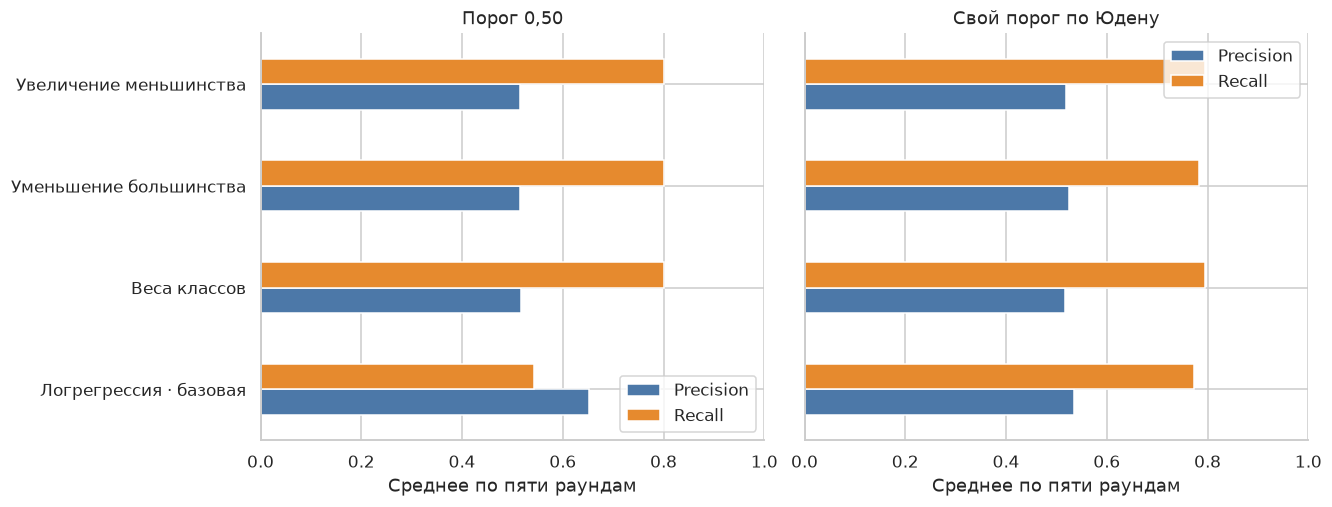

In [30]:
weighted = evaluate("Веса классов", make_pipeline(balance="weights"))
under = evaluate("Уменьшение большинства", make_pipeline(balance="under"))
over = evaluate("Увеличение меньшинства", make_pipeline(balance="over"))
balance_runs = [base, weighted, under, over]
display(score_table(balance_runs, ["ROC-AUC", "Брайер", *cut_metrics]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for ax, suffix in zip(axes, ["0,50", "J"]):
    values = pd.DataFrame({
        item["name"]: item["scores"][[f"Precision {suffix}", f"Recall {suffix}"]].mean()
        for item in balance_runs
    }).T
    values.columns = ["Precision", "Recall"]
    values.plot.barh(ax=ax, color=[BLUE, ORANGE])
    ax.set(xlim=(0, 1), xlabel="Среднее по пяти раундам",
           title="Порог 0,50" if suffix == "0,50" else "Свой порог по Юдену")
plt.show()

**Что дали веса и изменение числа примеров.** При пороге 0,50 базовая модель замечает около **54 из 100 ушедших**. Каждый из трёх способов балансировки поднимает это число примерно до **80 из 100**. При этом подтверждается примерно **52 из 100 предупреждений** вместо 65. Список для связи становится шире, а доля верных сигналов в нём уменьшается.

**Что меняется, если подобрать порог каждой модели.** У базовой модели Recall вырастает до **77,4%** за счёт изменения порога. У трёх вариантов с балансировкой после подбора порога Recall составляет **78,3–79,5%**. Часть выигрыша по числу обнаруженных уходов можно получить и при исходном соотношении классов. У базовой модели при подобранном пороге Precision составляет **53,6%**, у вариантов с балансировкой — **51,7–52,6%**.

**Что говорит основная метрика.** ROC-AUC у всех вариантов близок — от **0,8458 до 0,8463**. У базовой модели он равен **0,8462**. При этом оценка Брайера лучше у базовой модели — **0,1351** против **0,1653–0,1659** у вариантов с балансировкой. Для нашей задачи это аргумент сохранить исходное соотношение классов при проверке новых признаков.

**Почему дальше проверяем признаки.** В этом разделе мы меняли способ обучения при одном наборе признаков. В разделе 13 сделаем отдельное сравнение. Возьмём ту же базовую логистическую регрессию и по одному изменим её входные признаки. Так сможем оценить вклад каждого изменения. Все варианты из раздела 12 войдут в общее сравнение моделей в разделе 16.

## 13. Гипотезы из EDA и новые признаки

Проверим, помогает ли изменение входных признаков логистической регрессии. Каждую гипотезу проверяем по отдельности. Берём ту же базовую модель, то же соотношение классов и те же пять разбиений. За основной результат берём изменение ROC-AUC относительно базовой модели.

### 13.1. Что даёт логарифм стажа

В разделе 5.2 доля оттока выше у клиентов в первый год обслуживания. Хотим проверить, выиграет ли модель от более гибкого учёта стажа. В обычной логистической регрессии каждый дополнительный месяц даёт одинаковое изменение взвешенной суммы признаков, из которой модель затем рассчитывает вероятность. Добавим второй столбец со стажем на логарифмической шкале, чтобы вклад ещё одного месяца мог быть разным в начале и позже.

`log1p(tenure)` означает **натуральный логарифм от `1 + tenure`**. Единица позволяет обработать и нулевой стаж. При `tenure = 0` получаем логарифм от 1, то есть 0.

| Изменение стажа | Изменение на новой шкале |
|---|---|
| С 1 до 2 месяцев | С 0,693 до 1,099, прирост около 0,405 |
| С 60 до 61 месяца | С 4,111 до 4,127, прирост около 0,016 |

Исходный `tenure` оставляем, а `log1p(tenure)` добавляем к нему. Так модель может учитывать и общий эффект стажа, и особенно заметные изменения в первые месяцы. Станет ли ранжирование лучше, покажет валидация.

### 13.2. Нужен ли отдельный признак для первого года на помесячном договоре

В разделе 6.3 мы увидели, что доля оттока особенно велика у клиентов с помесячным договором в группе 0–12 месяцев. В исходных признаках стаж и тип договора уже есть. Добавим индикатор именно для их сочетания. Он равен **1**, если стаж не больше 12 месяцев и договор помесячный. Для всех остальных клиентов он равен **0**. Проверим, помогает ли модели отдельный коэффициент для этого сочетания.

### 13.3. Можно ли убрать накопленные начисления

В разделе 2.4 мы увидели, что `TotalCharges` тесно связан со стажем и ежемесячной платой. Обучим вариант, в котором исключим только `TotalCharges`. Так проверим, сохраняется ли качество, когда модели доступны стаж и месячная плата.

В первой таблице покажем метрики каждого варианта. Во второй таблице и на графике вычтем ROC-AUC базовой модели из ROC-AUC нового варианта в каждом из пяти раундов. Положительное значение означает улучшение на этом разбиении, оранжевый ромб показывает среднее изменение.

,ROC-AUC,Брайер,Precision J,Recall J
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.5356 ± 0.0203,0.7739 ± 0.0319
Логрегрессия + log1p(tenure),0.8502 ± 0.0129,0.1330 ± 0.0052,0.5212 ± 0.0237,0.8040 ± 0.0599
Первый год × помесячный договор,0.8469 ± 0.0127,0.1347 ± 0.0049,0.5328 ± 0.0312,0.7806 ± 0.0403
Без TotalCharges,0.8449 ± 0.0136,0.1355 ± 0.0059,0.5241 ± 0.0290,0.7866 ± 0.0240


Раунд,1,2,3,4,5,Среднее изменение
Логрегрессия + log1p(tenure),-0.0027,+0.0077,+0.0054,+0.0004,+0.0095,+0.0041
Первый год × помесячный договор,+0.0007,+0.0025,+0.0008,-0.0025,+0.0023,+0.0007
Без TotalCharges,-0.0008,-0.0005,-0.0013,-0.0015,-0.0023,-0.0013


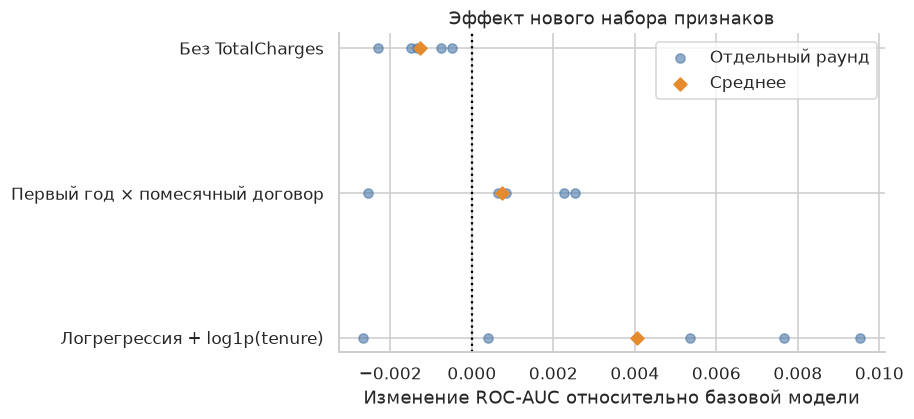

In [31]:
log_run = evaluate("Логрегрессия + log1p(tenure)", make_pipeline(feature="log_tenure"))
early = evaluate("Первый год × помесячный договор", make_pipeline(feature="early_monthly"))
no_total = evaluate("Без TotalCharges", make_pipeline(feature="without_total"))
feature_runs = [base, log_run, early, no_total]
display(score_table(feature_runs, ["ROC-AUC", "Брайер", "Precision J", "Recall J"]))
feature_deltas = pd.DataFrame({
    item["name"]: item["scores"]["ROC-AUC"] - base["scores"]["ROC-AUC"]
    for item in feature_runs[1:]
}).T
feature_deltas["Среднее изменение"] = feature_deltas.mean(axis=1)
display(feature_deltas.map(lambda x: f"{x:+.4f}"))
fig, ax = plt.subplots(figsize=(8.2, 3.7), layout="constrained")
for position, (name, changes) in enumerate(feature_deltas.iterrows()):
    ax.scatter(changes.loc[1:5].to_numpy(), [position] * 5, color=BLUE, alpha=0.6,
               label="Отдельный раунд" if position == 0 else None)
    ax.scatter(changes["Среднее изменение"], position, marker="D", color=ORANGE,
               label="Среднее" if position == 0 else None)
ax.axvline(0, ls=":", color="black")
ax.set(yticks=range(len(feature_deltas)), yticklabels=feature_deltas.index,
       xlabel="Изменение ROC-AUC относительно базовой модели", title="Эффект нового набора признаков")
ax.legend()
plt.show()

- **Логарифм стажа дал наибольшую прибавку.** Средний ROC-AUC вырос с **0,8462 до 0,8502**. Средняя разница до округления составила **+0,0041**, улучшение видно в четырёх из пяти раундов. Оценка Брайера также снизилась с 0,1351 до 0,1330. Этот вариант включаем в итоговое сравнение.
- **Индикатор первого года на помесячном договоре** дал **+0,0007** в среднем. Изменение качества в этом эксперименте небольшое.
- **Без `TotalCharges`** ROC-AUC снизился во всех пяти раундах, в среднем на **0,0013**. Значит, в этой конфигурации накопленные начисления дают модели небольшую дополнительную пользу. Сохраняем их в варианте с логарифмом стажа.

## 14. Другая модель — дерево решений

Логистическая регрессия складывает взвешенные признаки в оценку логарифма шансов. Дерево последовательно делит клиентов по признакам и может находить сочетания условий само. Начнём с дерева без ограничения глубины. При малом числе клиентов в листе его доля ушедших может оказаться слишком уверенной оценкой вероятности. Поэтому сравним и ROC-AUC, и Брайера.

In [32]:
tree_pipeline = make_pipeline(scale="none", family="tree")
tree_run = evaluate("Дерево · исходное", tree_pipeline)
display(score_table([base, tree_run], metrics))

,ROC-AUC,Брайер,"Precision 0,50","Recall 0,50"
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.6529 ± 0.0285,0.5431 ± 0.0460
Дерево · исходное,0.6573 ± 0.0117,0.2691 ± 0.0066,0.4925 ± 0.0120,0.5017 ± 0.0366


У исходного дерева ROC-AUC 0,6573 против 0,8462 у логистической регрессии. Брайер 0,2691 и 0,1351 соответственно. В следующем эксперименте ограничиваем глубину и размер листа, чтобы в листе оставалось больше клиентов для оценки частоты ухода.

## 15. Подбор гиперпараметров

В разделе 14 дерево без ограничения глубины заметно уступило базовой логистической регрессии. Проверим, насколько можно улучшить обе модели настройкой. Для каждой начнём с того же пайплайна и исходного набора признаков. Так измерим вклад подбора настроек отдельно от добавления признаков.

### 15.1. Что настраиваем

Гиперпараметры задаём до обучения. Они определяют, какие решения модель сможет выучить на данных и насколько сложными будут эти решения.

| Модель | Настройка | Зачем её проверяем |
|---|---|---|
| Логистическая регрессия | `C` управляет силой L2-регуляризации. Чем меньше `C`, тем сильнее штраф за большие коэффициенты. | Проверим, помогает ли изменить силу штрафа относительно `C = 1` в базовой модели. |
| Дерево решений | `max_depth` ограничивает число последовательных разбиений. | При меньшей глубине дерево использует более короткие правила. Проверим, лучше ли они работают на новых клиентах. |
| Дерево решений | `min_samples_leaf` задаёт минимальное число обучающих клиентов в конечной группе дерева, которую называют листом. | Вероятность ухода в листе рассчитывается по доле ушедших среди его клиентов. Чем больше минимум, тем больше наблюдений лежит в основе каждой оценки. |

### 15.2. Как ищем настройки

Используем `GridSearchCV`, перебор заранее заданных комбинаций. Для логистической регрессии берём шесть значений `C` от 0,01 до 100, равномерно распределённых по логарифмической шкале. Для дерева комбинируем глубины 3, 5 и 8 с минимальным размером листа 10 и 60. Для каждой модели получаем шесть конфигураций.

### 15.3. Как проверяем результат подбора

В каждом из пяти внешних раундов откладываем проверочную часть. На оставшихся клиентах оцениваем каждую комбинацию по **среднему ROC-AUC на трёх внутренних разбиениях**. Затем заново обучаем модель с выбранными настройками на всей обучающей части раунда и измеряем качество на внешней проверочной части.

В первой таблице сравниваем средние внешние результаты. Столбец `Δ ROC-AUC к исходной` показывает прибавку к исходной версии **той же модели**. Во второй таблице видны настройки, которые перебор выбрал для каждой модели в каждом раунде. Они могут различаться, поскольку данные для подбора в раундах меняются.

In [33]:
from functools import partial

from sklearn.model_selection import GridSearchCV

grids = {
    "logistic": {"model__C": np.geomspace(0.01, 100, 6)},
    "tree": {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [10, 60]},
}


def tune(pipeline, features, target, *, family):
    grid = GridSearchCV(
        pipeline, grids[family], cv=inner_cv, scoring="roc_auc",
        refit=False, error_score="raise",
    )
    grid.fit(features, target)
    return grid.best_params_

In [34]:
model_variants = [("logistic", "Логрегрессия", base), ("tree", "Дерево", tree_run)]
tuned_runs = []
for family, label, original_run in model_variants:
    search = partial(tune, family=family)
    tuned_runs.append(evaluate(f"{label} · GridSearchCV", original_run["pipeline"], search))

tuning_summary = score_table([base, tree_run, *tuned_runs], ["ROC-AUC", "Брайер"])
tuning_summary["Δ ROC-AUC к исходной"] = "исходная"
for tuned, (_, _, original_run) in zip(tuned_runs, model_variants, strict=True):
    difference = (tuned["scores"]["ROC-AUC"] - original_run["scores"]["ROC-AUC"]).mean()
    tuning_summary.loc[tuned["name"], "Δ ROC-AUC к исходной"] = f"{difference:+.4f}"
display(tuning_summary)

selected_parameters = {}
for tuned in tuned_runs:
    selected_parameters[tuned["name"]] = [
        ", ".join(f"{key.removeprefix('model__')} = {value:.4g}" for key, value in params.items())
        for params in tuned["params"]
    ]
display(pd.DataFrame(selected_parameters, index=pd.Index(range(1, 6), name="Внешний раунд")))

,ROC-AUC,Брайер,Δ ROC-AUC к исходной
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,исходная
Дерево · исходное,0.6573 ± 0.0117,0.2691 ± 0.0066,исходная
Логрегрессия · GridSearchCV,0.8464 ± 0.0145,0.1349 ± 0.0059,+0.0002
Дерево · GridSearchCV,0.8308 ± 0.0125,0.1407 ± 0.0063,+0.1735


,Логрегрессия · GridSearchCV,Дерево · GridSearchCV
Внешний раунд,,
1,C = 100,"max_depth = 8, min_samples_leaf = 60"
2,C = 100,"max_depth = 8, min_samples_leaf = 60"
3,C = 15.85,"max_depth = 5, min_samples_leaf = 60"
4,C = 100,"max_depth = 8, min_samples_leaf = 60"
5,C = 15.85,"max_depth = 8, min_samples_leaf = 60"


**Дерево заметно выиграло от настройки.** Средний ROC-AUC вырос с **0,6573 до 0,8308**, а оценка Брайера снизилась с **0,2691 до 0,1407**. Во всех пяти раундах перебор выбрал вариант с минимумом 60 клиентов в листе. Ограничения на глубину и размер листа улучшили результат дерева на внешних проверочных группах.

**У логистической регрессии прибавка небольшая.** Средний ROC-AUC вырос с **0,8462 до 0,8464**. Настроенное дерево по этой метрике уступило даже исходной регрессии. В разделе 16 сравним обе настроенные модели с остальными вариантами, включая регрессию с логарифмом стажа.

## 16. Выбор конфигурации до открытия теста

Сортируем модели по среднему внешнему ROC-AUC с полной точностью. При одинаковом значении предпочтём меньшую оценку Брайера, затем более простую конфигурацию. Стандартное отклонение помогает оценить масштаб различий между раундами. Маленькое преимущество в таблице может измениться на другой выборке. Порог выбранной модели окончательно определим по её внешним прогнозам на данных разработки. С этого момента конфигурация и порог зафиксированы.

In [35]:
all_runs = [base, plain, minmax, weighted, under, over, log_run, early, no_total, tree_run, *tuned_runs]
# Порядок для точного равенства двух метрик: меньше входов, затем меньше шагов подготовки.
tie_order = [no_total, plain, base, minmax, tree_run, weighted, log_run, early, under, over, *tuned_runs]
simplicity = {item["name"]: index for index, item in enumerate(tie_order)}
ranked = sorted(all_runs, key=lambda item: (-item["scores"]["ROC-AUC"].mean(),
                item["scores"]["Брайер"].mean(), simplicity[item["name"]]))
winner = ranked[0]
display(score_table(ranked, ["ROC-AUC", "Брайер", "Precision J", "Recall J"]))
final_cut = youden_threshold(y_train, winner["risk"])
final_model = clone(winner["pipeline"])
final_params = {}
if winner["search"] is not None:
    final_params = winner["search"](final_model, X_train, y_train)
    final_model.set_params(**final_params)
final_model.fit(X_train, y_train)
print(f"Выбрана модель «{winner['name']}». Порог предупреждения {final_cut:.6f}.")
print("Параметры поиска:", final_params or "фиксированная конфигурация")

,ROC-AUC,Брайер,Precision J,Recall J
Логрегрессия + log1p(tenure),0.8502 ± 0.0129,0.1330 ± 0.0052,0.5212 ± 0.0237,0.8040 ± 0.0599
Первый год × помесячный договор,0.8469 ± 0.0127,0.1347 ± 0.0049,0.5328 ± 0.0312,0.7806 ± 0.0403
Логрегрессия · GridSearchCV,0.8464 ± 0.0145,0.1349 ± 0.0059,0.5221 ± 0.0252,0.7880 ± 0.0344
Без масштабирования,0.8463 ± 0.0141,0.1350 ± 0.0058,0.5320 ± 0.0175,0.7886 ± 0.0443
Уменьшение большинства,0.8463 ± 0.0130,0.1659 ± 0.0064,0.5259 ± 0.0277,0.7826 ± 0.0349
Логрегрессия · базовая,0.8462 ± 0.0141,0.1351 ± 0.0058,0.5356 ± 0.0203,0.7739 ± 0.0319
Веса классов,0.8460 ± 0.0139,0.1653 ± 0.0060,0.5171 ± 0.0231,0.7953 ± 0.0446
Увеличение меньшинства,0.8458 ± 0.0143,0.1654 ± 0.0060,0.5181 ± 0.0222,0.7946 ± 0.0387
MinMaxScaler,0.8455 ± 0.0136,0.1353 ± 0.0057,0.5229 ± 0.0308,0.7926 ± 0.0242
Без TotalCharges,0.8449 ± 0.0136,0.1355 ± 0.0059,0.5241 ± 0.0290,0.7866 ± 0.0240


Выбрана модель «Логрегрессия + log1p(tenure)». Порог предупреждения 0.233549.
Параметры поиска: фиксированная конфигурация


По принятому правилу выбрана конфигурация «Логрегрессия + log1p(tenure)». Её средний ROC-AUC 0,8502, стандартное отклонение 0,0129, Брайер 0,1330. У ближайшего варианта «Первый год × помесячный договор» ROC-AUC 0,8469. Для итоговой проверки используем порог 0,2335.

## 17. Единственная итоговая проверка

Получим вероятности для всех 1 409 отложенных клиентов одним вызовом. По одним и тем же прогнозам проверим порядок рисков, точность вероятностей и последствия выбранного порога. В матрице строка обозначает наблюдаемый результат, столбец — решение модели. Каждая ячейка содержит количество абонентов.

,ROC-AUC,Брайер,Precision J,Recall J
Валидация · среднее ± стандартное отклонение,0.8502 ± 0.0129,0.1330 ± 0.0052,0.5212 ± 0.0237,0.8040 ± 0.0599
Итоговый тест,0.8476,0.1347,0.4905,0.8262


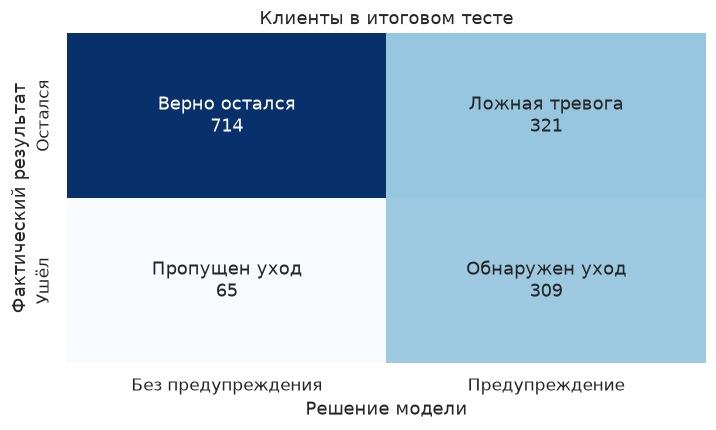

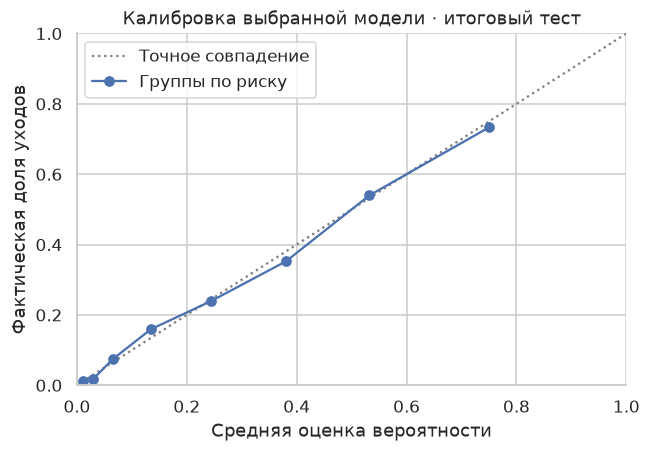

In [36]:
test_risk = pd.Series(final_model.predict_proba(X_test)[:, 1], index=X_test.index, name="risk")
test_alert = test_risk.ge(final_cut).astype(int)
assert test_risk.index.equals(y_test.index) and test_risk.between(0, 1).all()
test_scores = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_risk), "Брайер": brier_score_loss(y_test, test_risk),
    "Precision J": precision_score(y_test, test_alert, zero_division=0),
    "Recall J": recall_score(y_test, test_alert),
})
comparison = score_table([winner], list(test_scores.index))
comparison.index = ["Валидация · среднее ± стандартное отклонение"]
comparison.loc["Итоговый тест"] = test_scores.map(lambda x: f"{x:.4f}")
display(comparison)

matrix = confusion_matrix(y_test, test_alert, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
assert matrix.sum() == len(y_test)
labels = np.array([[f"Верно остался\n{tn}", f"Ложная тревога\n{fp}"],
                   [f"Пропущен уход\n{fn}", f"Обнаружен уход\n{tp}"]])
fig, ax = plt.subplots(figsize=(6.4, 3.8), layout="constrained")
sns.heatmap(matrix, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Без предупреждения", "Предупреждение"], yticklabels=["Остался", "Ушёл"])
ax.set(xlabel="Решение модели", ylabel="Фактический результат", title="Клиенты в итоговом тесте")
plt.show()
test_cal = calibration_plot(y_test, test_risk, "Калибровка выбранной модели · итоговый тест")

Из 374 фактически ушедших модель обнаружила 309, пропустила 65. Из 630 предупреждений 321 оказались ложными. ROC-AUC составил 0,8476, Брайер 0,1347. В группе самых высоких прогнозов из 176 клиентов средний прогноз составил 75,0%, фактическая доля ухода — 73,3%.

### 17.1. Как выглядит результат для абонента

Возьмём шесть клиентов через равные интервалы отсортированного риска. Это примеры работы правила во всём диапазоне оценок. Качество по всем клиентам показано выше. Вероятность округляем только для вывода, решение принимаем по полному значению.

In [37]:
predictions = pd.DataFrame({"Вероятность ухода": test_risk,
                            "Решение": test_alert.map({0: "Без предупреждения", 1: "Предупреждение"}),
                            "Фактический Churn": clients.loc[X_test.index, "Churn"]})
assert predictions.index.equals(test_risk.index) and predictions.index.is_unique
assert predictions["Фактический Churn"].map({"No": 0, "Yes": 1}).equals(y_test)
examples = predictions.sort_values("Вероятность ухода").iloc[np.linspace(0, len(predictions)-1, 6, dtype=int)]
display(examples.assign(**{"Вероятность ухода": examples["Вероятность ухода"].map("{:.2%}".format)}))

,Вероятность ухода,Решение,Фактический Churn
customerID,,,
8619-IJNDK,0.52%,Без предупреждения,No
8763-KIAFH,3.14%,Без предупреждения,No
4946-EDSEW,10.53%,Без предупреждения,Yes
2924-KHUVI,27.92%,Предупреждение,No
9167-APMXZ,51.42%,Предупреждение,No
5178-LMXOP,93.79%,Предупреждение,Yes


Например, у клиента 5178-LMXOP оценка ухода 93,8%, решение при выбранном пороге — «Предупреждение», фактический Churn — Yes. Это индивидуальная оценка. Проверить смысл таких процентов можно на группе похожих прогнозов, как на графике калибровки.

### 17.2. Кого модель пропускает и кого отмечает зря

Матрица ошибок показывает, сколько всего клиентов получили неверное решение при выбранном пороге. Посмотрим, **в каких группах эти ошибки встречаются чаще**. Сравним типы договора и интервалы стажа из раздела 5.2. Используем те же прогнозы для отложенных клиентов и тот же порог.

- **Пропущенные уходы.** Из всех действительно ушедших в группе считаем долю тех, про кого модель не предупредила.
- **Ложные предупреждения.** Из всех оставшихся в группе считаем долю тех, кого модель отметила как клиентов с высоким риском.

В скобках показаны число ошибок и число клиентов, среди которых искали этот вид ошибки. Например, 2 из 5 и 20 из 50 дают одинаковую долю, а наблюдений во второй группе больше.

In [38]:
left = y_test.eq(1)
alert = test_alert.eq(1)
tenure_groups = segments.set_index("customerID")["tenure_group"]
error_clients = X_test[["Contract"]].assign(
    tenure_group=tenure_groups.reindex(X_test.index),
    left=left,
    stayed=~left,
    missed=left & ~alert,
    false_alert=~left & alert,
)
assert error_clients["tenure_group"].notna().all()


def count_group_errors(column):
    return error_clients.groupby(column, observed=True).agg(
        clients=("left", "size"), left=("left", "sum"), stayed=("stayed", "sum"),
        missed=("missed", "sum"), false_alert=("false_alert", "sum"),
    )


def error_rate(errors, total):
    if total == 0:
        return "—"
    return f"{errors / total:.1%} ({errors} из {total})"


contract_errors = count_group_errors("Contract").reindex(CONTRACT_ORDER)
tenure_errors = count_group_errors("tenure_group")
assert (contract_errors[["missed", "false_alert"]].sum().to_numpy() == [fn, fp]).all()
assert (tenure_errors[["missed", "false_alert"]].sum().to_numpy() == [fn, fp]).all()

contract_names = {"Month-to-month": "Помесячный", "One year": "Годовой", "Two year": "Двухлетний"}
error_counts = pd.concat({
    "Тип договора": contract_errors.rename(index=contract_names),
    "Стаж, мес.": tenure_errors,
}, names=["Разрез", "Группа"])

error_table = pd.DataFrame({
    "Всего клиентов": error_counts["clients"],
    "Пропущенные уходы": [
        error_rate(errors, total) for errors, total in zip(error_counts["missed"], error_counts["left"])
    ],
    "Ложные предупреждения": [
        error_rate(errors, total) for errors, total in zip(error_counts["false_alert"], error_counts["stayed"])
    ],
})
display(error_table)

Всего клиентов Пропущенные уходы  \
Разрез       Группа                                         
Тип договора Помесячный             773  9.1% (30 из 329)   
             Годовой                300  72.2% (26 из 36)   
             Двухлетний             336   100.0% (9 из 9)   
Стаж, мес.   0–12                   449  8.8% (19 из 215)   
             13–24                  206   13.3% (8 из 60)   
             25–36                  163   17.5% (7 из 40)   
             37–48                  141  54.2% (13 из 24)   
             49–60                  174   42.1% (8 из 19)   
             61–72                  276  62.5% (10 из 16)   

                        Ложные предупреждения  
Разрез       Группа                            
Тип договора Помесячный    65.3% (290 из 444)  
             Годовой        11.7% (31 из 264)  
             Двухлетний       0.0% (0 из 327)  
Стаж, мес.   0–12          64.5% (151 из 234)  
             13–24          45.2% (66 из 146)  
             25–36          26.0% (32 из 123)  
             37–48          24.8% (29 из 117)  
             49–60          20.6% (32 из 155)  
             61–72           4.2% (11 из 260)

**Ложные предупреждения.** На помесячные договоры приходится **290 из 321** ложного предупреждения. Среди оставшихся клиентов с таким договором модель отметила **65,3%**. По стажу контраст тоже заметен. В первый год предупреждение получили **151 из 234** оставшихся, а при стаже 61–72 месяца — **11 из 260**.

**Пропущенные уходы.** Модель пропустила **30 из 329** уходов на помесячных договорах, **26 из 36** на годовых и **9 из 9** на двухлетних. У двухлетних договоров всего девять событий, поэтому доля для этой группы чувствительна к исходу нескольких клиентов.

**Гипотеза для следующей проверки.** Возможно, даже среди клиентов только с помесячным договором ложные предупреждения чаще встречаются в первый год обслуживания. В таблице выше стаж и договор рассмотрены по отдельности. На новых данных можно сравнить доли ложных предупреждений по стажу внутри одного договора и посмотреть, сохранится ли разница.

### 17.3. Кому звонить первым

Сортируем 1 409 тестовых клиентов от наибольшей оценённой вероятности ухода к наименьшей. При равных оценках используем порядок `customerID`. Фактический исход нужен для проверки уже составленного списка. Покажем первые пять позиций, затем сравним списки разного размера.

Если команда может позвонить примерно 10%, 20% или 30% клиентов, берём соответствующее число верхних позиций с округлением до ближайшего целого. Отдельно покажем объём списка по ранее выбранному порогу Юдена. **Доля уходов в списке** показывает, сколько уходов приходится на 100 звонков. **Охват всех уходов** показывает, сколько из 374 уходов попало в список.

In [39]:
ranked_clients = predictions.sort_values(
    ["Вероятность ухода", "customerID"], ascending=[False, True],
)
top_clients = ranked_clients[["Вероятность ухода", "Фактический Churn"]].head(5).copy()
top_clients.insert(0, "Место", np.arange(1, len(top_clients) + 1))
top_clients["Вероятность ухода"] = top_clients["Вероятность ухода"].map("{:.2%}".format)
display(top_clients)

total_clients = len(ranked_clients)
cumulative_churn = ranked_clients["Фактический Churn"].eq("Yes").cumsum()
total_churned = int(cumulative_churn.iloc[-1])
contact_budget = int(test_alert.sum())
contact_options = pd.Series(
    {f"Первые {share:.0%} списка": round(share * total_clients) for share in (0.10, 0.20, 0.30)},
    name="Контактов",
)
contact_options.loc["Порог Юдена"] = contact_budget

contact_summary = contact_options.to_frame()
contact_summary["Ушедших в списке"] = cumulative_churn.iloc[contact_options.to_numpy() - 1].to_numpy()
contact_summary["Доля уходов в списке"] = contact_summary["Ушедших в списке"] / contact_options
contact_summary["Охват всех уходов"] = contact_summary["Ушедших в списке"] / total_churned
assert total_churned == int(y_test.sum())
assert contact_budget == tp + fp and contact_summary.loc["Порог Юдена", "Ушедших в списке"] == tp

display(contact_summary.style.format({
    "Доля уходов в списке": "{:.1%}",
    "Охват всех уходов": "{:.1%}",
}))

,Место,Вероятность ухода,Фактический Churn
customerID,,,
5178-LMXOP,1,93.79%,Yes
0295-PPHDO,2,92.41%,Yes
1069-XAIEM,3,90.97%,Yes
3722-WPXTK,4,89.34%,Yes
0970-ETWGE,5,89.15%,Yes


,Контактов,Ушедших в списке,Доля уходов в списке,Охват всех уходов
Первые 10% списка,141,109,77.3%,29.1%
Первые 20% списка,282,192,68.1%,51.3%
Первые 30% списка,423,247,58.4%,66.0%
Порог Юдена,630,309,49.0%,82.6%


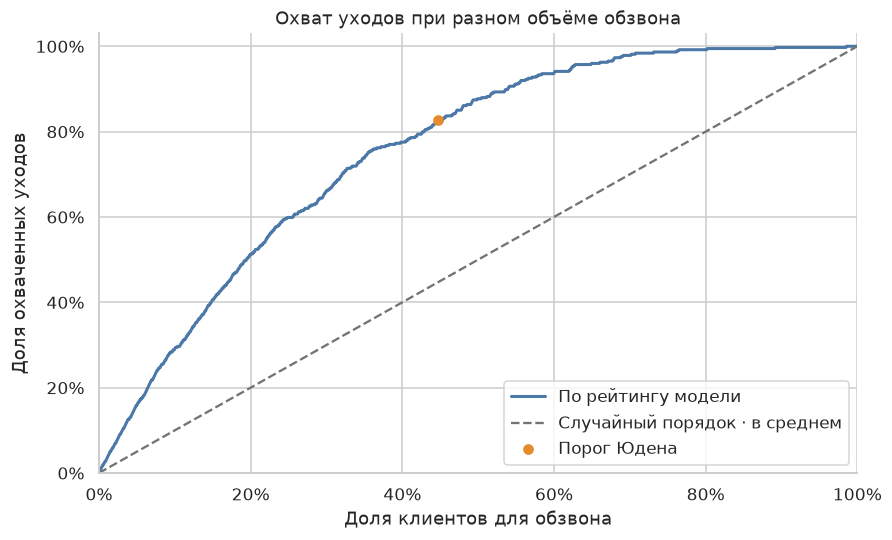

In [40]:
from matplotlib.ticker import PercentFormatter

share_contacted = np.arange(total_clients + 1) / total_clients
share_churn_detected = np.r_[0, cumulative_churn.to_numpy()] / total_churned

fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
ax.plot(share_contacted, share_churn_detected, color=BLUE, linewidth=2, label="По рейтингу модели")
ax.plot([0, 1], [0, 1], color="0.45", linestyle="--", label="Случайный порядок · в среднем")
ax.scatter(contact_budget / total_clients, tp / total_churned, color=ORANGE,
           zorder=3, label="Порог Юдена")
ax.set(xlabel="Доля клиентов для обзвона", ylabel="Доля охваченных уходов",
       xlim=(0, 1), ylim=(0, 1.03), title="Охват уходов при разном объёме обзвона")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(loc="lower right")
plt.show()

**При ограниченном бюджете начнём с верхних позиций.** Первые 282 клиентов (около 20% тестовой выборки) включают **192 ушедших**. Это **51,3%** всех уходов. При случайном выборе того же объёма ожидаемый охват составляет около 20%, что соответствует пунктирной линии.

Порог Юдена включает **630** клиентов, или около **44,7%** тестовой выборки. Он охватывает **82,6%** уходов. График показывает, сколько уходов можно охватить при разных объёмах звонков.

## 18. Какие признаки связаны с риском

Перемешаем значения одного исходного столбца между проверочными клиентами. Если ROC-AUC снижается, выбранной модели была полезна информация этого столбца. Повторим перемешивание восемь раз и усредним изменение. Перед перемешиванием заполняем пустые начисления по исходному стажу клиента, как в модели. После перестановки возможны искусственные сочетания услуг, срока и начислений. Это особенно важно для интерпретации связанных полей. Для производных признаков пайплайн заново рассчитывает значения из изменённого входа. Проверка служит интерпретации уже зафиксированной модели.

Само падение ROC-AUC не задаёт направление связи. Для пяти наиболее важных входов рядом покажем группы данных разработки с наибольшей и наименьшей наблюдаемой долей ухода. Для числовых признаков сравним четыре интервала примерно одинакового размера по известным значениям, для категорий — исходные значения. Различия между группами включают влияние других характеристик.

In [41]:
from sklearn.inspection import permutation_importance

# Сначала применяем принятое правило к реальным парам (стаж, начисления).
# Иначе перемешивание стажа перенесло бы пропуск к вымышленному клиенту с ненулевым стажем.
X_for_importance = prepare_features(X_test)
assert X_for_importance.columns.equals(X_test.columns) and X_for_importance.notna().all().all()
permuted = permutation_importance(final_model, X_for_importance, y_test, scoring="roc_auc",
                                 n_repeats=8, random_state=SEED)
importance = pd.Series(permuted.importances_mean, index=X_test.columns).sort_values(ascending=False)
factors = []
for column in importance.head(5).index:
    values = X_train[column]
    if column in NUMERIC:
        bins = pd.qcut(values, 4, duplicates="drop")
        limits = values.groupby(bins, observed=True).agg(["min", "max"])
        labels = {interval: f"{row['min']:g}–{row['max']:g}" for interval, row in limits.iterrows()}
        values = bins.cat.rename_categories(labels)
    rates = y_train.groupby(values, observed=True).agg(["mean", "size"]).sort_values("mean")
    low, high = rates.iloc[0], rates.iloc[-1]
    factors.append({"Признак": column, "Падение ROC-AUC": importance[column],
                    "Группа с большей долей ухода": str(rates.index[-1]),
                    "Доля ухода ↑": high["mean"], "Клиентов ↑": int(high["size"]),
                    "Группа с меньшей долей ухода": str(rates.index[0]),
                    "Доля ухода ↓": low["mean"], "Клиентов ↓": int(low["size"])})
factor_table = pd.DataFrame(factors).set_index("Признак")
report = factor_table.copy()
for col in ["Доля ухода ↑", "Доля ухода ↓"]:
    report[col] = report[col].map("{:.1%}".format)
report["Падение ROC-AUC"] = report["Падение ROC-AUC"].map("{:.4f}".format)
display(report)

,Падение ROC-AUC,Группа с большей долей ухода,Доля ухода ↑,Клиентов ↑,Группа с меньшей долей ухода,Доля ухода ↓,Клиентов ↓
Признак,,,,,,,
tenure,0.0736,0–9,49.7%,1463,56–72,8.1%,1408
Contract,0.0486,Month-to-month,42.7%,3102,Two year,2.9%,1359
InternetService,0.0397,Fiber optic,42.1%,2483,No,7.2%,1214
MonthlyCharges,0.0211,70.55–90,37.0%,1406,18.4–35.65,10.9%,1409
StreamingTV,0.0048,No,33.1%,2226,No internet service,7.2%,1214


Самые большие средние потери ROC-AUC при перемешивании наблюдались для tenure, Contract, InternetService. Для tenure доли ухода в группах 0–9 и 56–72 составили 49,7% и 8,1%. Стаж, сумма начислений и условия договора взаимосвязаны. Важность отдельного поля зависит от того, какая информация осталась в других полях.

### 18.1. Как стаж и договор меняют прогноз модели

В таблице выше стаж и тип договора вошли в число наиболее важных признаков. Теперь сравним **оценки риска для трёх вариантов одного профиля**. Возьмём клиента из выборки разработки со стажем 24 месяца и помесячным договором. Среди таких клиентов выберем того, чья месячная плата ближе всего к медиане группы. Его остальные характеристики, например подключённые услуги и способ оплаты, используем во всех трёх вариантах.

1. **Стаж от 6 до 24 месяцев.** Сохраняем помесячный договор и текущую плату. Для обоих вариантов рассчитываем накопленные начисления как стаж, умноженный на месячную плату. Это сценарий с постоянной ценой. Он показывает совместное изменение прогноза при большем стаже и соответствующей накопленной сумме.
2. **Помесячный договор и двухлетний.** Сравниваем варианты при стаже 24 месяца, той же месячной плате и тех же накопленных начислениях. Меняем только поле `Contract` в профиле.

Передаём эти варианты уже обученному пайплайну. Он сам рассчитывает `log1p(tenure)` и кодирует категории. Вероятности в таблице — ответы модели для заданных сценариев.

In [42]:
reference_group = X_train.loc[X_train["Contract"].eq("Month-to-month") & X_train["tenure"].eq(24)]
monthly = reference_group["MonthlyCharges"]
reference_id = (monthly - monthly.median()).abs().idxmin()
reference = reference_group.loc[[reference_id]]
monthly_fee = float(reference["MonthlyCharges"].iloc[0])

six_months = reference.assign(tenure=6, TotalCharges=6 * monthly_fee)
monthly_contract = reference.assign(TotalCharges=24 * monthly_fee)
two_year_contract = monthly_contract.assign(Contract="Two year")

scenarios = pd.concat([six_months, monthly_contract, two_year_contract], ignore_index=True)
scenarios.index = pd.Index(
    ["6 месяцев, помесячный", "24 месяца, помесячный", "24 месяца, двухлетний"], name="Сценарий",
)
scenario_risk = pd.Series(final_model.predict_proba(scenarios)[:, 1], index=scenarios.index)

scenario_table = scenarios[["tenure", "MonthlyCharges", "TotalCharges"]].rename(columns={
    "tenure": "Стаж, мес.", "MonthlyCharges": "Месячная плата", "TotalCharges": "Накопленные начисления",
})
scenario_table["Оценка риска ухода"] = scenario_risk.map("{:.1%}".format)
display(scenario_table.round(2))

,"Стаж, мес.",Месячная плата,Накопленные начисления,Оценка риска ухода
Сценарий,,,,
"6 месяцев, помесячный",6,79.85,479.1,62.2%
"24 месяца, помесячный",24,79.85,1916.4,40.0%
"24 месяца, двухлетний",24,79.85,1916.4,11.1%


При помесячном договоре переход от 6 к 24 месяцам стажа при той же плате и соответствующем росте накопленных начислений снизил оценку модели с **62,2% до 40,0%**.

При одинаковом стаже 24 месяца, одинаковых начислениях и остальных признаках оценка составила **40,0%** для помесячного договора и **11,1%** для двухлетнего. Это сравнение ответов модели на заданные профили. Чтобы оценить, как реальная смена договора влияет на уход, понадобятся данные об изменениях договора и последующих исходах.

## 19. Ответ оператору и границы применения

### Результат для оператора

**Модель.** Для ранжирования клиентов выбрана модель «Логрегрессия + log1p(tenure)». На отложенных клиентах её ROC-AUC составил 0,848. При пороге 0,2335 она выявила 82,6% уходов, а 49,0% предупреждений оказались верными. При ограниченном числе звонков оператор может брать верхнюю часть списка из раздела 17.3.

**Факторы риска.** В данных разработки повышенная доля ухода наблюдается у клиентов с коротким стажем, помесячным договором и оптоволоконным интернетом. Стаж, тип договора и технология интернета лидируют и по падению ROC-AUC при перемешивании. Доли и размеры сравниваемых групп приведены в разделе 18. Индивидуальные оценки с идентификаторами приведены в разделе 17.1. Ошибки по группам разобраны в 17.2, а сравнения прогнозов для заданных профилей — в 18.1.

### Что показал тест

После выбора модели и порога мы проверили прогнозы на 1 409 отложенных абонентах из того же CSV. Этот результат показывает, насколько хорошо модель различает ушедших и оставшихся по признакам из одной выгрузки. Команда смотрела на весь CSV на этапе разведочного анализа, и эти наблюдения подсказали гипотезы о признаках.

### Как проверить прогноз на следующий месяц

В этом CSV у каждого клиента одна строка. В ней указаны услуги, договор, начисления и факт ухода за последний месяц. Для прогноза вперёд важно знать, **какие данные оператор уже видел на дату прогноза** и **кто ушёл после неё**.

Например, на **1 апреля** берём активных клиентов. Используем их стаж, договор и начисления, известные на эту дату. По ним оцениваем вероятность ухода **в течение апреля**. В начале мая узнаём, кто действительно ушёл, и сравниваем прогнозы с результатом. Если очередная сумма начислений появилась после 1 апреля, она могла бы использоваться только в следующих прогнозах. Для такой проверки нужны выгрузки с датами и история ухода.

### Экономика обзвона

Сравним две стратегии при бюджете на 630 звонков, как при пороге Юдена. Первая берёт верхние позиции рейтинга, вторая выбирает столько же абонентов случайно. Для случайного списка ожидаемое число уходов равно размеру списка, умноженному на долю ушедших во всей тестовой выборке.

**Допущения учебного сценария.** Один звонок стоит **50 ₽**. Сохранённый абонент приносит **3 000 ₽ дополнительной маржи за следующие 12 месяцев** после затрат на обслуживание и возможное предложение. Звонок помогает удержать **10% клиентов, которые иначе ушли бы**. Предполагаем одинаковый эффект для таких клиентов в обоих списках. В этом сценарии сам звонок оплачивается для каждого клиента, скидка автоматически не выдаётся.

Выгоду считаем как ожидаемую маржу от удержанных абонентов за вычетом затрат на все звонки. Фактический эффект удержания и суммы затрат оператору предстоит измерить.

In [43]:
cost_per_call = 50
margin_per_retained = 3_000
retention_effect = 0.10

expected_churned = pd.Series({
    "По рейтингу модели": int(cumulative_churn.iloc[contact_budget - 1]),
    "Случайный выбор": contact_budget * total_churned / total_clients,
}, name="Ушедших в списке").rename_axis("Порядок обзвона")

call_cost = contact_budget * cost_per_call
expected_retained = expected_churned * retention_effect
campaign = pd.DataFrame({
    "Звонков": contact_budget,
    "Ушедших в списке": expected_churned,
    "Ожидаемо удержано": expected_retained,
    "Затраты на звонки, ₽": call_cost,
    "Ожидаемый эффект, ₽": expected_retained * margin_per_retained - call_cost,
})
break_even_effect = call_cost / (expected_churned.loc["По рейтингу модели"] * margin_per_retained)
false_alert_cost = fp * cost_per_call

display(campaign.style.format({
    "Ушедших в списке": "{:.1f}",
    "Ожидаемо удержано": "{:.1f}",
    "Затраты на звонки, ₽": "{:,.0f}",
    "Ожидаемый эффект, ₽": "{:,.0f}",
}))
print(f"Затраты на ложные предупреждения: {false_alert_cost:,} ₽.")
print(f"Доля удержанных среди клиентов, которые иначе ушли бы, для окупаемости: {break_even_effect:.2%}.")

,Звонков,Ушедших в списке,Ожидаемо удержано,"Затраты на звонки, ₽","Ожидаемый эффект, ₽"
Порядок обзвона,,,,,
По рейтингу модели,630,309.0,30.9,"31,500","61,200"
Случайный выбор,630,167.2,16.7,"31,500","18,667"


Затраты на ложные предупреждения: 16,050 ₽.
Доля удержанных среди клиентов, которые иначе ушли бы, для окупаемости: 3.40%.


**Результат сценария.** При 630 звонках рейтинг включает **309 ушедших**. В случайном списке того же размера ожидаем около **167**. При принятых допущениях маржа за вычетом звонков составляет **61 200 ₽** у списка модели и около **18 667 ₽** у случайного списка.

**Цена ложных тревог.** 321 звонок оставшимся абонентам обходится в **16 050 ₽**. Эта сумма входит в общий бюджет звонков **31 500 ₽**. Среди тех, кто иначе ушёл бы, звонок даёт в среднем **300 ₽ ожидаемой маржи** до его стоимости при допущении об эффекте 10%. Чтобы покрыть бюджет звонков по списку модели, нужно удержать около **3,4%** клиентов из этой группы.

### Как проверить пользу звонков

В пилоте случайно делим сопоставимых клиентов из верхней части рейтинга на две группы. Одной группе звоним, для второй сохраняем обычный порядок работы. Затем сравниваем долю ушедших за одинаковый период, фактические затраты и дополнительную маржу. Это позволит оценить вклад самого звонка в удержание и обновить расчёт окупаемости.